# AIT511 Flight Price Prediction — Complete EDA, Experiments, and Final Model

## Project objective

Predict domestic flight ticket prices using the supplied training data, compare class-taught regression models with the boosting models permitted by the TA, investigate the data through visualizations and correlation analysis, perform controlled model experiments, and generate the final Kaggle submission.

**Best confirmed Kaggle result reported by the user:** `submission_v6_sqrt_lgbm_fullfit.csv` — **0.78042**.

This notebook includes expanded EDA and correlations, OLS / polynomial / Ridge / Lasso / Decision Tree / Random Forest baselines, LightGBM target and feature experiments, LightGBM tuning, class-specific models, CatBoost, XGBoost screening, a two-stage high-fare model, a V5-style target-encoding blend reproduction, feature importance, and the final submission generation.

### Reproducibility and safety notes

- `id` is used only for row matching in the output CSV and exploratory auditing; it is not a predictive feature.
- No ID-order positions, block ranks, neighbour-price interpolation, nearest-row, or KNN-like features are used, following the TA's direction.
- Cross-validation feature aggregates are fitted on the training fold only.
- All validation predictions are converted back to original price units before calculating metrics.
- The highest-scoring submitted candidate used a specific compact configuration (100 LightGBM trees, square-root target, one seed). The notebook records this configuration separately so the output file can be reproduced exactly. It also runs more extensive CV experiments; those should guide generalization judgment rather than being confused with the already-scored configuration.
- A Kaggle score is not derivable from the hidden labels; 0.78042 is the user's reported past result, not a promise that a new submission will score the same.



In [1]:
import os, re, time, warnings, math
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import KFold, train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler, PolynomialFeatures
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from time import perf_counter
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
import lightgbm as lgb

try:
    from catboost import CatBoostRegressor
    CATBOOST_AVAILABLE = True
except Exception as exc:
    CATBOOST_AVAILABLE = False
    print("CatBoost is unavailable; CatBoost experiments will be skipped.", repr(exc))

warnings.filterwarnings("ignore")
SEED = 42
FAST_MODE = False  # Set True only for a quick smoke test; False is the full experiment.
N_SPLITS = 2 if FAST_MODE else 3
CV_SEEDS = [42] if FAST_MODE else [42, 7, 2024]
LGB_TREES = 100 if FAST_MODE else 900
CAT_TREES = 120 if FAST_MODE else 1200
FINAL_SEEDS = [42] if FAST_MODE else [42, 101, 7, 2024, 555]
N_JOBS = 4
OUT_DIR = Path("/kaggle/working") if Path("/kaggle/working").exists() else Path.cwd()
OUT_DIR.mkdir(parents=True, exist_ok=True)
HIGH_FARE_QUANTILE = 0.90

print("LightGBM:", lgb.__version__)
print("CatBoost available:", CATBOOST_AVAILABLE)
print("FAST_MODE:", FAST_MODE, "CV seeds:", CV_SEEDS, "folds per seed:", N_SPLITS)

LightGBM: 4.6.0
CatBoost available: True
FAST_MODE: False CV seeds: [42, 7, 2024] folds per seed: 3


## 1. Load and audit the files

Works with Kaggle input folders, files in the current directory, a `data/` folder, or the uploaded `/mnt/data` files. The dataset's `id` is excluded from model features.

In [2]:
def find_csv(name, required=True):
    aliases = {
        "train.csv": ["train.csv", "train(1).csv"],
        "test.csv": ["test.csv", "test(1).csv"],
        "submission.csv": ["submission.csv", "submission(1).csv"],
    }.get(name, [name])
    roots = [Path("/kaggle/input"), Path("data"), Path("."), Path("/mnt/data")]
    seen = set()
    for root in roots:
        if not root.exists():
            continue
        for alias in aliases:
            direct = root / alias
            if direct.is_file() and str(direct.resolve()) not in seen:
                return direct
        for alias in aliases:
            try:
                for path in root.rglob(alias):
                    key = str(path.resolve())
                    if path.is_file() and key not in seen:
                        seen.add(key)
                        return path
            except (PermissionError, OSError):
                pass
    if required:
        raise FileNotFoundError(f"Cannot find {name}. Put train.csv/test.csv in the working folder or upload them to Kaggle.")
    return None

train_path = find_csv("train.csv")
test_path = find_csv("test.csv")
train = pd.read_csv(train_path)
test = pd.read_csv(test_path)

print("Train:", train_path, train.shape)
print("Test :", test_path, test.shape)
print("Train columns:", train.columns.tolist())
assert "price" in train.columns and "price" not in test.columns
assert "id" in train.columns and "id" in test.columns
assert len(test) == 4520, f"Expected 4,520 test rows, found {len(test)}"
assert train["price"].notna().all() and np.isfinite(train["price"]).all()
assert test["id"].notna().all() and test["id"].is_unique

print("\nMissing values in train:", int(train.isna().sum().sum()))
print("Missing values in test :", int(test.isna().sum().sum()))
print("Price summary:\n", train["price"].describe(percentiles=[.5, .9, .95, .99, .995, .999]))
print("\nPrice by class:\n", train.groupby("flight_class")["price"].agg(["count", "mean", "median", "std", "max"]))
print("\nUnique cities:", sorted(set(train.source_city) | set(train.destination_city)))
print("Unique airlines:", train.airline.nunique(), "unique flights:", train.flight.nunique())
print("\nNote: ID is not included in any feature list below.")

Train: /kaggle/input/competitions/flight-price-prediction/train.csv (18076, 12)
Test : /kaggle/input/competitions/flight-price-prediction/test.csv (4520, 11)
Train columns: ['id', 'airline', 'flight', 'source_city', 'departure_time', 'stops', 'arrival_time', 'destination_city', 'flight_class', 'duration', 'days_left', 'price']

Missing values in train: 0
Missing values in test : 0
Price summary:
 count    18076.000000
mean       280.264550
std        221.965133
min          0.000000
50%        234.000000
90%        519.000000
95%        656.250000
99%       1016.000000
99.5%     1292.000000
99.9%     2103.000000
max       8996.000000
Name: price, dtype: float64

Price by class:
               count        mean  median         std   max
flight_class                                             
Business       7365  393.955465   323.0  278.746354  8996
Economy       10711  202.089441   194.0  121.342204  1071

Unique cities: ['Los Angeles', 'Sacramento', 'San Diego', 'San Francisco', 'San

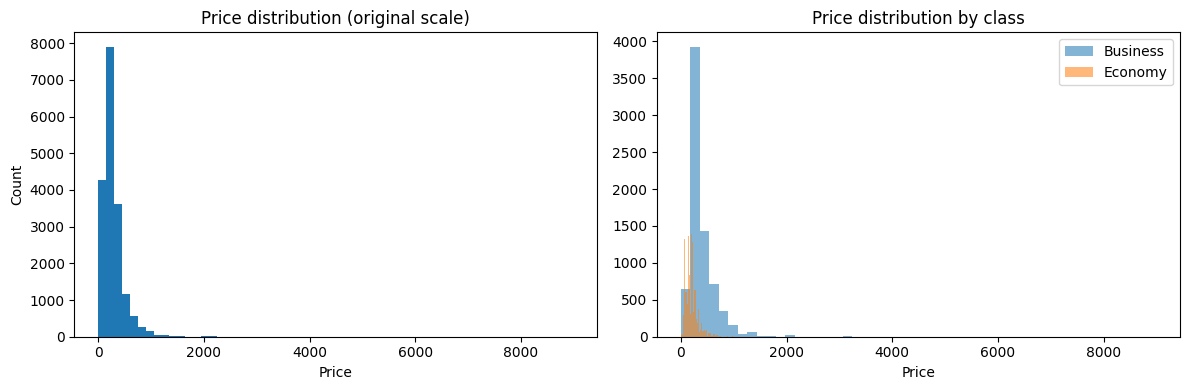

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(train["price"], bins=60)
axes[0].set_title("Price distribution (original scale)")
axes[0].set_xlabel("Price")
axes[0].set_ylabel("Count")
for cls, values in train.groupby("flight_class")["price"]:
    axes[1].hist(values, bins=50, alpha=0.55, label=str(cls))
axes[1].set_title("Price distribution by class")
axes[1].set_xlabel("Price")
axes[1].legend()
plt.tight_layout()
plt.show()

## 2. Data quality, distributions, and categorical composition

This section documents data quality before modeling. The identifier `id` is inspected only for data audit purposes; it is **not** used as a predictive feature. Training data has the target `price`; test data does not.


,train_dtype,train_missing,test_dtype,test_missing,train_unique,test_unique
airline,object,0,object,0.0,7,6.0
arrival_time,object,0,object,0.0,6,6.0
days_left,int64,0,int64,0.0,44,44.0
departure_time,object,0,object,0.0,6,6.0
destination_city,object,0,object,0.0,5,5.0
duration,float64,0,float64,0.0,576,357.0
flight,object,0,object,0.0,1123,790.0
flight_class,object,0,object,0.0,2,2.0
id,int64,0,int64,0.0,18076,4520.0
price,int64,0,NaN,NaN,768,NaN


Exact duplicate training rows: 0
Duplicate training IDs: 0
Duplicate test IDs: 0
Target skewness: 7.070
Target kurtosis: 170.245


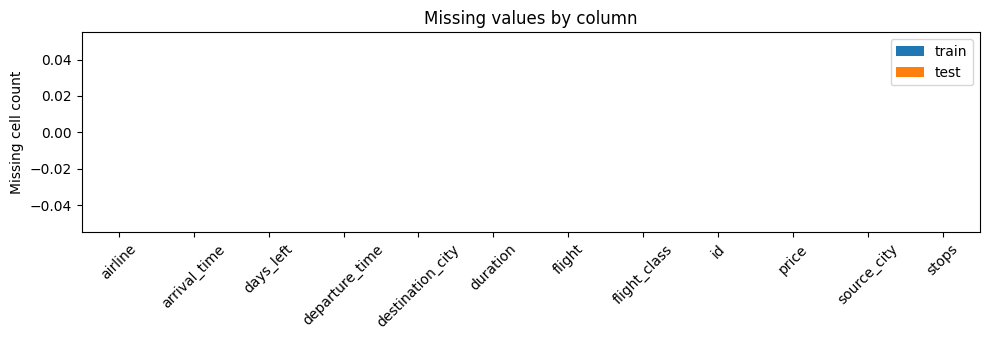

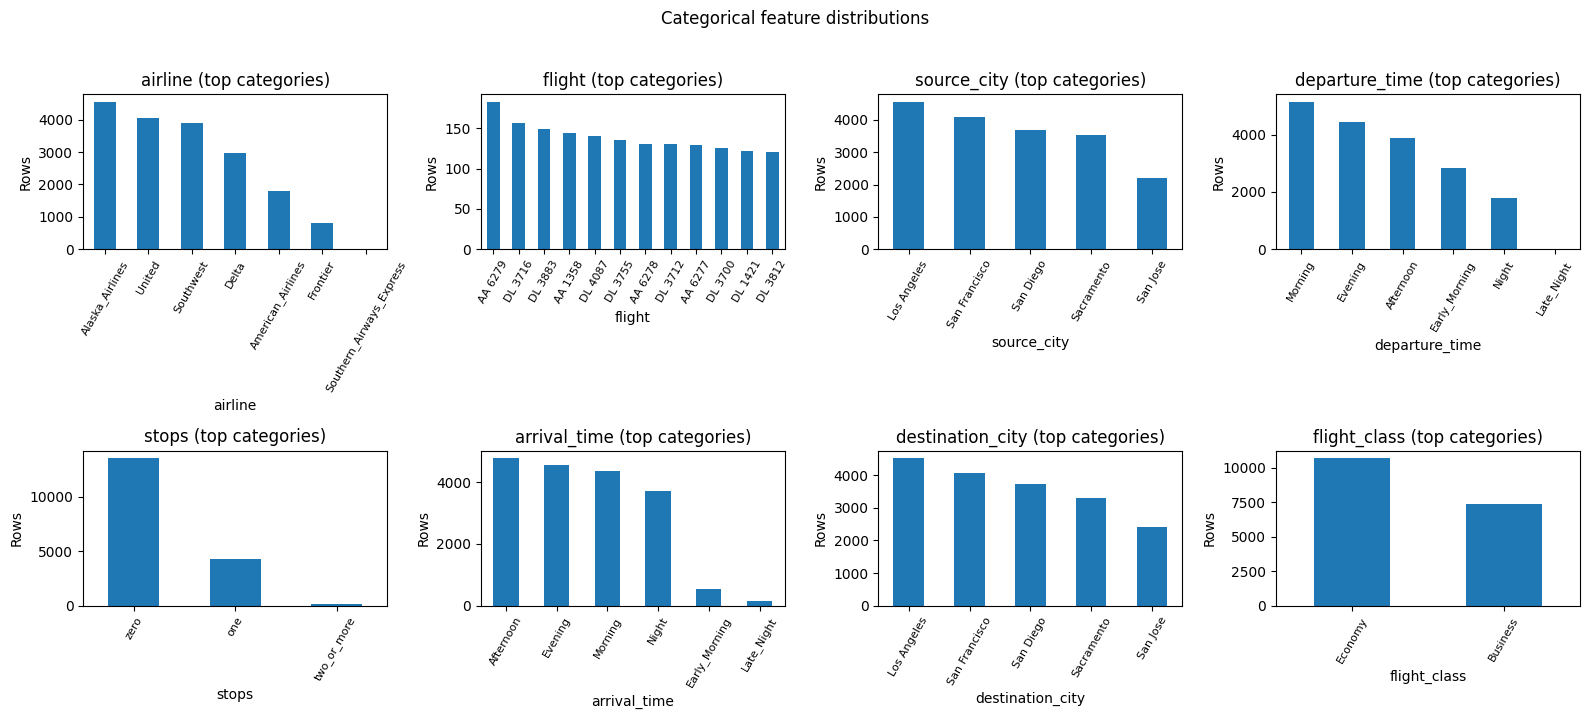

In [4]:
# Row counts, data types, missingness, duplicates, and category cardinality
quality = pd.DataFrame({
    "train_dtype": train.dtypes.astype(str),
    "train_missing": train.isna().sum(),
    "test_dtype": test.reindex(columns=train.columns.drop("price")).dtypes.astype(str),
    "test_missing": test.isna().sum(),
})
quality["train_unique"] = train.nunique(dropna=False)
quality["test_unique"] = test.reindex(columns=train.columns.drop("price")).nunique(dropna=False)
display(quality)
print(f"Exact duplicate training rows: {train.duplicated().sum():,}")
print(f"Duplicate training IDs: {train['id'].duplicated().sum():,}")
print(f"Duplicate test IDs: {test['id'].duplicated().sum():,}")
print(f"Target skewness: {train['price'].skew():.3f}")
print(f"Target kurtosis: {train['price'].kurtosis():.3f}")

fig, ax = plt.subplots(figsize=(10, 3.5))
missing = pd.DataFrame({
    "train": train.isna().sum(),
    "test": test.reindex(columns=train.columns.drop("price")).isna().sum()
}).fillna(0)
missing.plot(kind="bar", ax=ax)
ax.set_title("Missing values by column")
ax.set_ylabel("Missing cell count")
ax.tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.show()

categorical_cols_raw = [c for c in train.columns if train[c].dtype == "object"]
fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for ax, col in zip(axes.ravel(), categorical_cols_raw):
    counts = train[col].value_counts().head(12)
    counts.plot(kind="bar", ax=ax)
    ax.set_title(f"{col} (top categories)")
    ax.set_ylabel("Rows")
    ax.tick_params(axis="x", rotation=60, labelsize=8)
for ax in axes.ravel()[len(categorical_cols_raw):]:
    ax.axis("off")
plt.suptitle("Categorical feature distributions", y=1.02)
plt.tight_layout()
plt.show()


## 3. Target distribution and price relationships

The price distribution is right-skewed, especially because a small number of Business fares are much more expensive than typical tickets. Log-scale visualizations help show the bulk of the distribution without deleting the expensive cases.


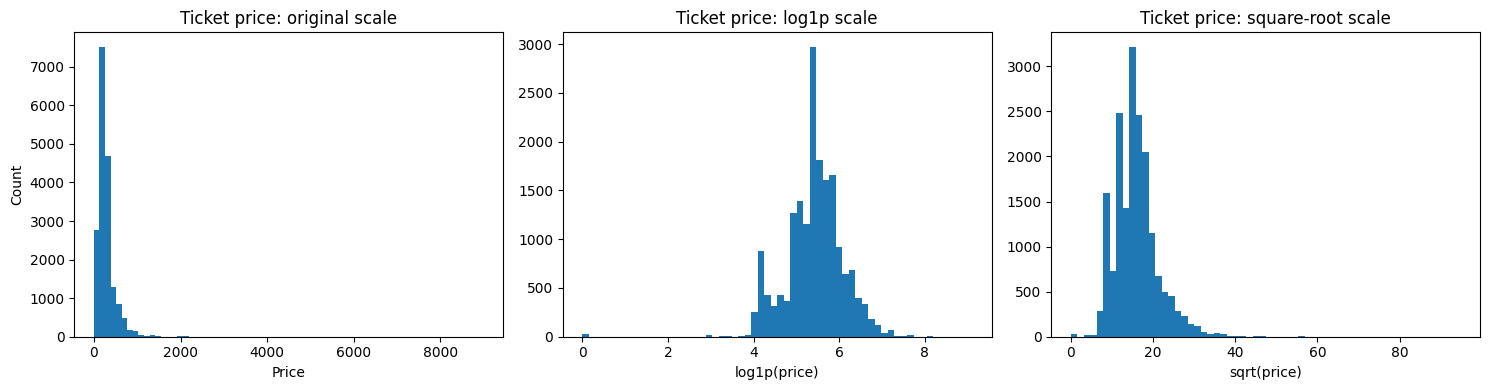

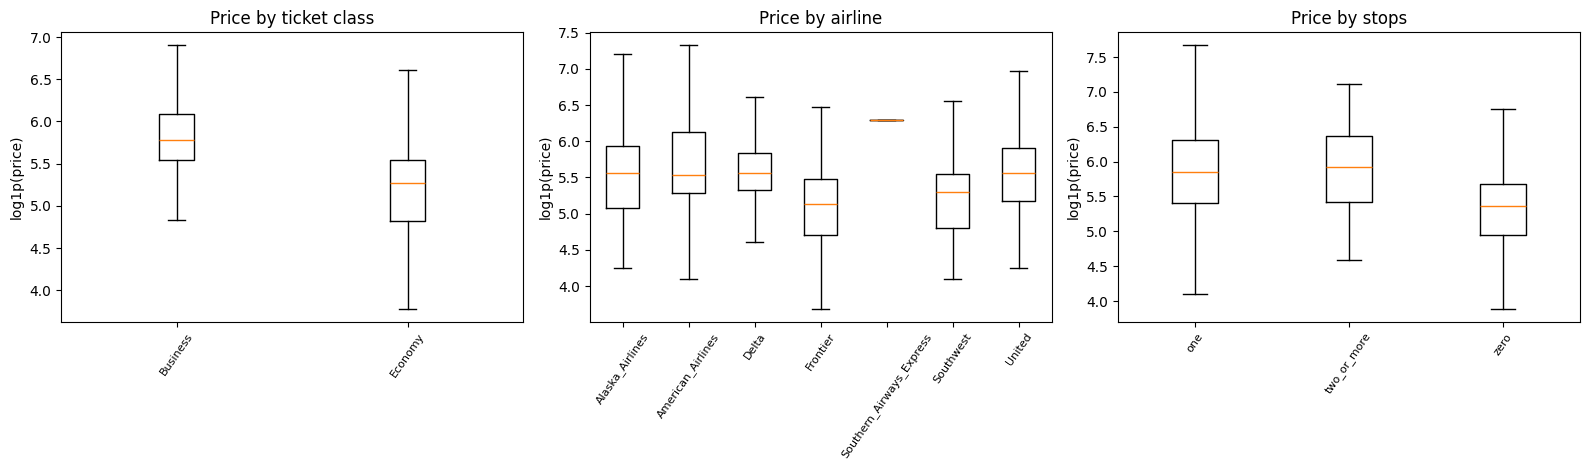

,count,mean,median,std,min,max
flight_class,,,,,,
Business,7365,393.96,323.0,278.75,0,8996
Economy,10711,202.09,194.0,121.34,0,1071


In [5]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
axes[0].hist(train["price"], bins=70)
axes[0].set_title("Ticket price: original scale")
axes[0].set_xlabel("Price")
axes[0].set_ylabel("Count")
axes[1].hist(np.log1p(train["price"]), bins=60)
axes[1].set_title("Ticket price: log1p scale")
axes[1].set_xlabel("log1p(price)")
axes[2].hist(np.sqrt(train["price"]), bins=60)
axes[2].set_title("Ticket price: square-root scale")
axes[2].set_xlabel("sqrt(price)")
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))
plot_specs = [("flight_class", "Price by ticket class"), ("airline", "Price by airline"), ("stops", "Price by stops")]
for ax, (col, title) in zip(axes, plot_specs):
    groups = [np.log1p(g["price"].to_numpy()) for _, g in train.groupby(col, observed=False)]
    labels = [str(k) for k, _ in train.groupby(col, observed=False)]
    ax.boxplot(groups, labels=labels, showfliers=False)
    ax.set_title(title)
    ax.set_ylabel("log1p(price)")
    ax.tick_params(axis="x", rotation=55, labelsize=8)
plt.tight_layout()
plt.show()

# Distribution by class gives context for later target transformations.
display(train.groupby("flight_class")["price"].agg(["count", "mean", "median", "std", "min", "max"]).round(2))


flight_class,Business,Economy
days_bin,,
1–7,375.0,259.0
8–14,329.0,224.0
15–21,297.0,189.0
22–30,294.0,139.0
31–45,285.0,109.0


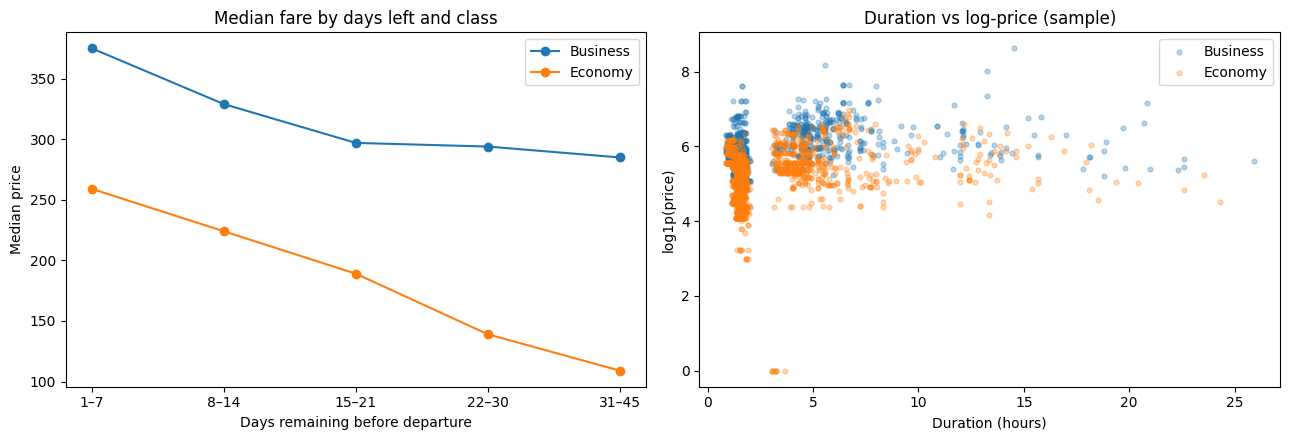

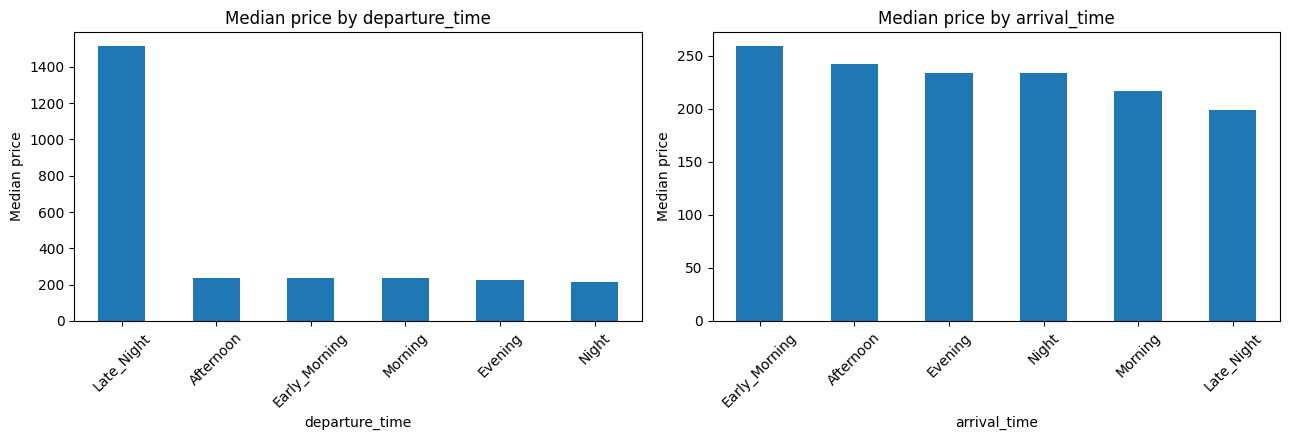

In [6]:
# Booking lead time: median fares by days-left bins and class
lead = train[["days_left", "flight_class", "price"]].copy()
lead["days_bin"] = pd.cut(lead["days_left"], bins=[0, 7, 14, 21, 30, 45],
                          labels=["1–7", "8–14", "15–21", "22–30", "31–45"], include_lowest=True)
lead_summary = lead.groupby(["days_bin", "flight_class"], observed=False)["price"].median().unstack()
display(lead_summary)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for cls in lead_summary.columns:
    axes[0].plot(lead_summary.index.astype(str), lead_summary[cls], marker="o", label=cls)
axes[0].set_title("Median fare by days left and class")
axes[0].set_xlabel("Days remaining before departure")
axes[0].set_ylabel("Median price")
axes[0].legend()

sample = train.sample(min(3500, len(train)), random_state=42)
for cls, grp in sample.groupby("flight_class"):
    axes[1].scatter(grp["duration"], np.log1p(grp["price"]), s=12, alpha=0.3, label=cls)
axes[1].set_title("Duration vs log-price (sample)")
axes[1].set_xlabel("Duration (hours)")
axes[1].set_ylabel("log1p(price)")
axes[1].legend()
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, col in zip(axes, ["departure_time", "arrival_time"]):
    summary_cat = train.groupby(col, observed=False)["price"].median().sort_values(ascending=False)
    summary_cat.plot(kind="bar", ax=ax)
    ax.set_title(f"Median price by {col}")
    ax.set_ylabel("Median price")
    ax.tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.show()


## 4. Correlation analysis

Pearson correlation measures linear association; Spearman correlation measures monotonic association by rank. Categorical variables cannot be interpreted through a raw Pearson matrix until encoded, so their price relationships are examined using group summaries separately. `id` is shown only as a diagnostic and is excluded from every model.


Pearson correlations (id is audit-only):


,id,duration,days_left,price
id,1.000,-0.018,0.978,-0.235
duration,-0.018,1.000,-0.018,0.281
days_left,0.978,-0.018,1.000,-0.229
price,-0.235,0.281,-0.229,1.000


Spearman correlations (id is audit-only):


,id,duration,days_left,price
id,1.000,0.002,0.980,-0.366
duration,0.002,1.000,0.001,0.174
days_left,0.980,0.001,1.000,-0.365
price,-0.366,0.174,-0.365,1.000


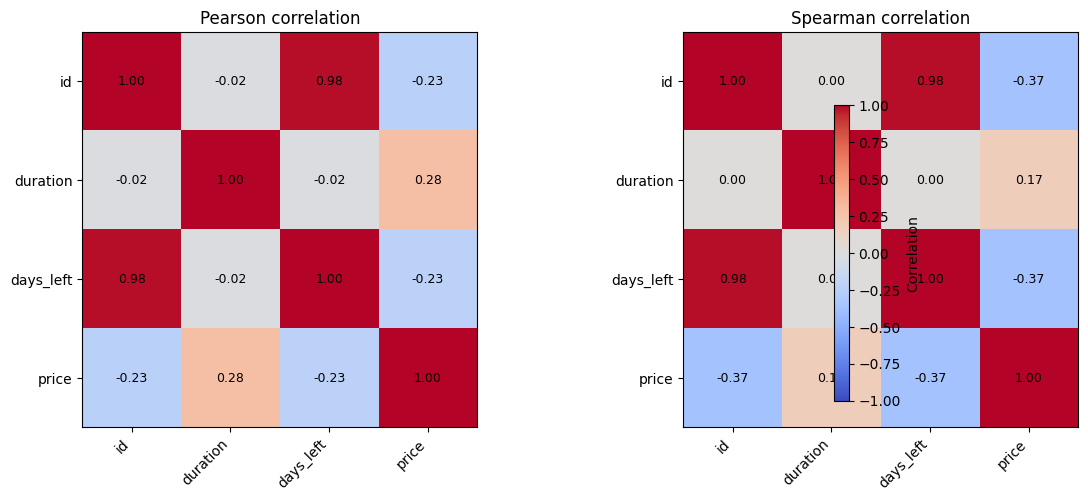

,Pearson,Spearman
id,-0.235,-0.366
days_left,-0.229,-0.365
duration,0.281,0.174


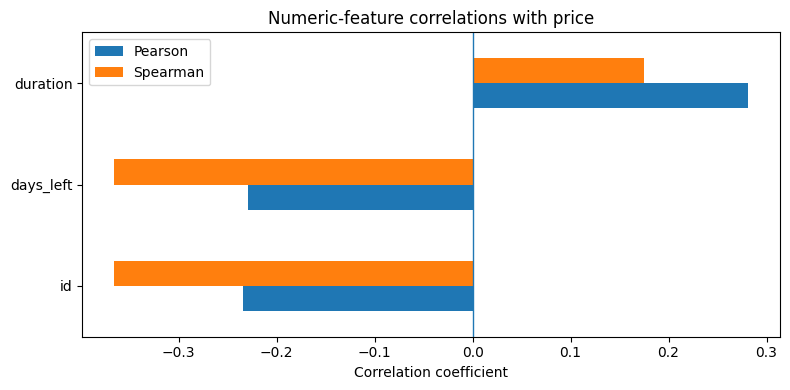

,count,median,mean
airline,,,
Southern_Airways_Express,1,543.0,543.00
Delta,2972,259.0,286.53
Alaska_Airlines,4554,259.0,302.62
United,4058,259.0,319.03
American_Airlines,1797,253.0,349.44
Southwest,3895,199.0,197.84
Frontier,799,168.0,178.58


,count,median,mean
source_city,,,
Sacramento,3521,279.0,353.48
San Jose,2217,254.0,341.19
Los Angeles,4561,224.0,258.33
San Diego,3691,220.0,234.07
San Francisco,4086,207.0,250.33


,count,median,mean
destination_city,,,
Sacramento,3303,269.0,337.82
San Jose,2424,264.0,362.01
Los Angeles,4533,224.0,258.69
San Diego,3743,219.0,235.97
San Francisco,4073,215.0,249.66


,count,median,mean
departure_time,,,
Late_Night,6,1514.0,2743.33
Afternoon,3893,234.0,284.96
Early_Morning,2820,234.0,294.46
Morning,5144,234.0,298.02
Evening,4436,224.0,260.79
Night,1777,217.0,236.36


,count,median,mean
arrival_time,,,
Early_Morning,525,259.0,268.81
Afternoon,4785,242.0,301.93
Evening,4549,234.0,295.49
Night,3701,234.0,274.24
Morning,4364,217.0,249.59
Late_Night,152,199.0,209.36


,count,median,mean
stops,,,
two_or_more,193,370.0,425.74
one,4324,347.0,431.53
zero,13559,214.0,229.95


,count,median,mean
flight_class,,,
Business,7365,323.0,393.96
Economy,10711,194.0,202.09


In [7]:
numeric_audit_cols = ["id", "duration", "days_left", "price"]
pearson_corr = train[numeric_audit_cols].corr(method="pearson")
spearman_corr = train[numeric_audit_cols].corr(method="spearman")
print("Pearson correlations (id is audit-only):")
display(pearson_corr.round(3))
print("Spearman correlations (id is audit-only):")
display(spearman_corr.round(3))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
for ax, matrix, title in [(axes[0], pearson_corr, "Pearson correlation"), (axes[1], spearman_corr, "Spearman correlation")]:
    im = ax.imshow(matrix.to_numpy(), vmin=-1, vmax=1, cmap="coolwarm")
    ax.set_xticks(range(len(matrix.columns)), matrix.columns, rotation=45, ha="right")
    ax.set_yticks(range(len(matrix.index)), matrix.index)
    ax.set_title(title)
    for i in range(matrix.shape[0]):
        for j in range(matrix.shape[1]):
            ax.text(j, i, f"{matrix.iloc[i, j]:.2f}", ha="center", va="center", fontsize=9)
fig.colorbar(im, ax=axes, shrink=0.8, label="Correlation")
plt.tight_layout()
plt.show()

corr_to_price = pd.DataFrame({
    "Pearson": pearson_corr["price"].drop("price"),
    "Spearman": spearman_corr["price"].drop("price"),
}).sort_values("Pearson")
display(corr_to_price.round(3))
fig, ax = plt.subplots(figsize=(8, 4))
corr_to_price.plot(kind="barh", ax=ax)
ax.axvline(0, linewidth=1)
ax.set_title("Numeric-feature correlations with price")
ax.set_xlabel("Correlation coefficient")
plt.tight_layout()
plt.show()

# Categorical price associations: medians are descriptive, not causal effects.
cat_assoc_cols = ["airline", "source_city", "destination_city", "departure_time", "arrival_time", "stops", "flight_class"]
for col in cat_assoc_cols:
    display(train.groupby(col, observed=False)["price"].agg(["count", "median", "mean"]).sort_values("median", ascending=False).round(2).rename_axis(col))


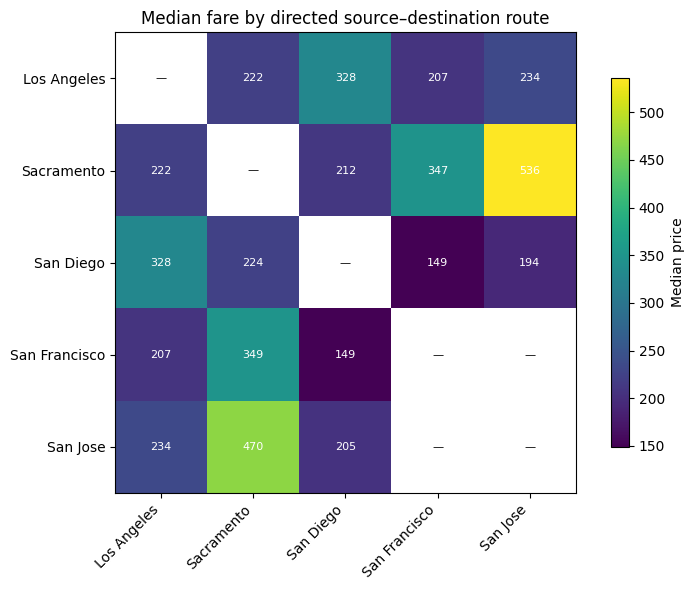

,airline,flight_class,count,median
8,Southern_Airways_Express,Business,1,543.0
10,United,Business,2015,349.0
2,American_Airlines,Business,940,345.0
4,Delta,Business,1559,309.0
0,Alaska_Airlines,Business,2503,304.0
6,Frontier,Business,347,220.0
5,Delta,Economy,1413,215.0
3,American_Airlines,Economy,857,205.0
9,Southwest,Economy,3895,199.0
11,United,Economy,2043,176.0


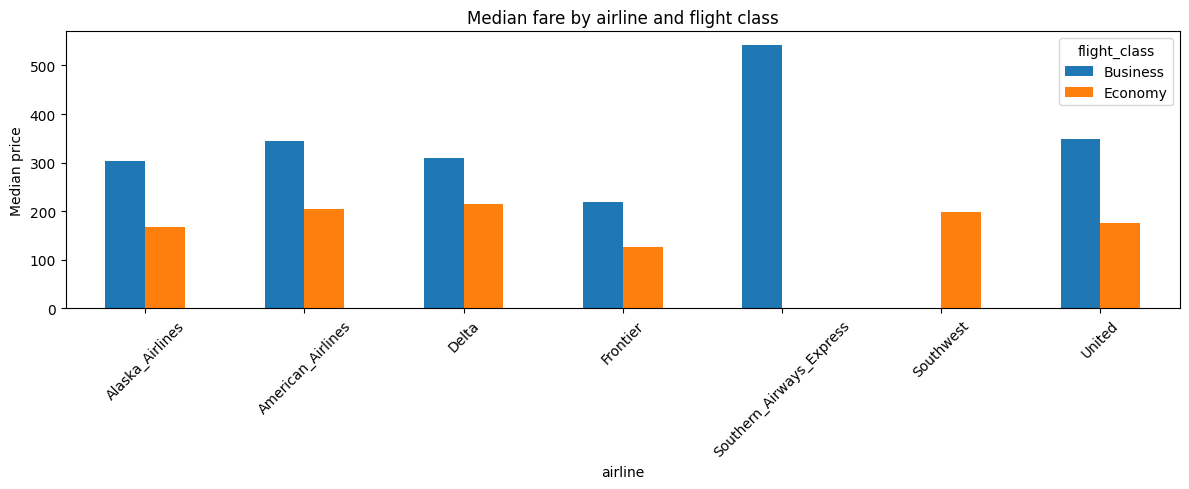

In [8]:
# Directed route matrix: each cell is the median training price for that source -> destination.
route_median = train.pivot_table(index="source_city", columns="destination_city", values="price", aggfunc="median")
fig, ax = plt.subplots(figsize=(8, 6))
im = ax.imshow(route_median.to_numpy(), cmap="viridis")
ax.set_xticks(range(len(route_median.columns)), route_median.columns, rotation=45, ha="right")
ax.set_yticks(range(len(route_median.index)), route_median.index)
ax.set_title("Median fare by directed source–destination route")
for i in range(route_median.shape[0]):
    for j in range(route_median.shape[1]):
        val = route_median.iloc[i, j]
        ax.text(j, i, "—" if pd.isna(val) else f"{val:.0f}", ha="center", va="center", fontsize=8,
                color="white" if pd.notna(val) else "black")
fig.colorbar(im, ax=ax, shrink=0.8, label="Median price")
plt.tight_layout()
plt.show()

# Price by airline and class, with group counts printed for context.
airline_class = train.groupby(["airline", "flight_class"], observed=False)["price"].agg(["count", "median"]).reset_index()
display(airline_class.sort_values(["flight_class", "median"], ascending=[True, False]).round(2))
fig, ax = plt.subplots(figsize=(12, 5))
medians = train.pivot_table(index="airline", columns="flight_class", values="price", aggfunc="median")
medians.plot(kind="bar", ax=ax)
ax.set_title("Median fare by airline and flight class")
ax.set_ylabel("Median price")
ax.tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.show()


## 5. Class-taught regression baselines

This section demonstrates the core AIT511 model families on the original predictors: OLS, polynomial regression, Ridge, Lasso, and Decision Tree Regression. Random Forest is included because the TA explicitly allowed it. A fixed 80/20 holdout is used for this baseline comparison; these metrics are not the final Kaggle estimate and are not directly comparable to the repeated-CV results below.


,model,validation_R2,validation_RMSE,validation_MAE,fit_seconds
0,Random Forest Regression,0.4858,191.2569,47.9250,18.7902
1,Lasso Regression (alpha=0.01),0.4660,194.9013,75.7922,31.0427
2,Polynomial Regression (degree 2),0.4564,196.6510,74.7086,0.3118
3,OLS / Multiple Linear Regression,0.4527,197.3052,75.3560,0.2561
4,Decision Tree Regression,0.4353,200.4165,52.4747,0.5412
5,Ridge Regression (alpha=10),0.4224,202.6932,77.1506,0.1236


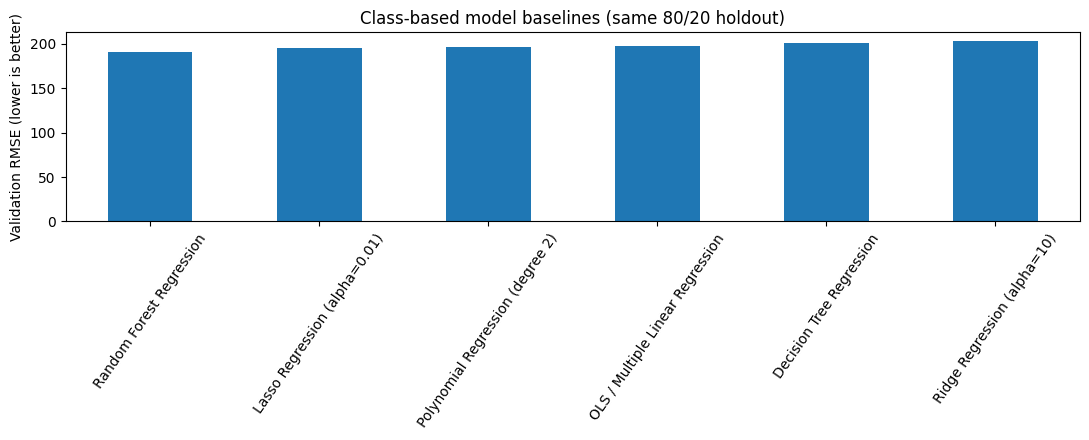

In [9]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler, PolynomialFeatures
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
from sklearn.model_selection import train_test_split
from time import perf_counter

RAW_CAT_COLS = ["airline", "flight", "source_city", "departure_time", "stops", "arrival_time", "destination_city", "flight_class"]
RAW_NUM_COLS = ["duration", "days_left"]
X_raw = train[RAW_CAT_COLS + RAW_NUM_COLS].copy()  # `id` intentionally excluded
Y_raw = train["price"].astype(float).to_numpy()
idx_train, idx_valid = train_test_split(np.arange(len(train)), test_size=0.20, random_state=42,
                                        stratify=train["flight_class"])
Xtr_raw, Xva_raw = X_raw.iloc[idx_train], X_raw.iloc[idx_valid]
ytr_raw, yva_raw = Y_raw[idx_train], Y_raw[idx_valid]


def make_raw_preprocessor(polynomial=False):
    if polynomial:
        num_pipe = Pipeline([("scale", StandardScaler()), ("poly", PolynomialFeatures(degree=2, include_bias=False))])
    else:
        num_pipe = StandardScaler()
    return ColumnTransformer([
        ("numeric", num_pipe, RAW_NUM_COLS),
        ("categorical", OneHotEncoder(handle_unknown="ignore"), RAW_CAT_COLS),
    ], remainder="drop")

baseline_models = {
    "OLS / Multiple Linear Regression": (make_raw_preprocessor(False), LinearRegression()),
    "Polynomial Regression (degree 2)": (make_raw_preprocessor(True), LinearRegression()),
    "Ridge Regression (alpha=10)": (make_raw_preprocessor(False), Ridge(alpha=10.0)),
    "Lasso Regression (alpha=0.01)": (make_raw_preprocessor(False), Lasso(alpha=0.01, max_iter=20000, tol=1e-3)),
    "Decision Tree Regression": (make_raw_preprocessor(False), DecisionTreeRegressor(max_depth=16, min_samples_leaf=3, random_state=42)),
    "Random Forest Regression": (make_raw_preprocessor(False), RandomForestRegressor(n_estimators=150, max_depth=20, min_samples_leaf=3,
                                                                                    max_features=0.8, n_jobs=N_JOBS, random_state=42)),
}
base_rows = []
for model_name, (preprocessor, estimator) in baseline_models.items():
    pipe = Pipeline([("preprocess", preprocessor), ("model", estimator)])
    started = perf_counter()
    pipe.fit(Xtr_raw, ytr_raw)
    elapsed = perf_counter() - started
    pred = np.maximum(pipe.predict(Xva_raw), 0)
    base_rows.append({
        "model": model_name,
        "validation_R2": r2_score(yva_raw, pred),
        "validation_RMSE": float(np.sqrt(mean_squared_error(yva_raw, pred))),
        "validation_MAE": mean_absolute_error(yva_raw, pred),
        "fit_seconds": elapsed,
    })

class_baseline_results = pd.DataFrame(base_rows).sort_values("validation_R2", ascending=False).reset_index(drop=True)
display(class_baseline_results.round(4))
class_baseline_results.to_csv(OUT_DIR / "class_baseline_results.csv", index=False) if "OUT_DIR" in globals() else class_baseline_results.to_csv("class_baseline_results.csv", index=False)

fig, ax = plt.subplots(figsize=(11, 4.5))
class_baseline_results.sort_values("validation_RMSE").plot(x="model", y="validation_RMSE", kind="bar", ax=ax, legend=False)
ax.set_title("Class-based model baselines (same 80/20 holdout)")
ax.set_ylabel("Validation RMSE (lower is better)")
ax.set_xlabel("")
ax.tick_params(axis="x", rotation=55)
plt.tight_layout()
plt.show()


## 6. Deterministic feature engineering and fold-fitted aggregates

The engineered features describe the flight rather than the row's position in the file. City coordinates below are approximate city-centre coordinates and are used only to compute great-circle distance. Frequency and route-duration mappings are fitted separately inside each CV training fold to keep the validation protocol consistent.

In [10]:
STOPS_MAP = {"zero": 0, "one": 1, "two_or_more": 2}
DAY_BINS = [-np.inf, 7, 14, 21, 30, np.inf]
DAY_LABELS = ["1wk", "2wk", "3wk", "4wk", "5wk+"]
TIME_ORDER = {"Early_Morning": 0, "Morning": 1, "Afternoon": 2, "Evening": 3, "Night": 4, "Late_Night": 5}
TIME_HOUR = {"Early_Morning": 4, "Morning": 9, "Afternoon": 14, "Evening": 18, "Night": 21, "Late_Night": 23}

# Approximate city-centre coordinates; no target or ID-derived information is used.
CITY_COORDS = {
    "Los Angeles": (34.0522, -118.2437),
    "San Diego": (32.7157, -117.1611),
    "San Francisco": (37.7749, -122.4194),
    "San Jose": (37.3382, -121.8863),
    "Sacramento": (38.5816, -121.4944),
}
EARTH_RADIUS_KM = 6371.0088

BASE_CATS = ["airline", "source_city", "destination_city", "departure_time", "arrival_time",
             "route", "time_slot", "airline_route", "days_bucket"]
BASE_NUMS = ["stops_num", "is_business", "duration", "days_left", "log_duration"]
V4_NUMS = BASE_NUMS + ["departure_order", "arrival_order", "dep_hour", "arr_hour", "hour_diff_mod24",
                       "overnight", "route_duration_mean", "duration_vs_route_mean"]
TIME_EXTRA_NUMS = ["log_days_left", "inv_days_left"]
FREQ_NUMS = ["log_flight_freq", "log_route_freq", "log_airline_route_freq", "log_flight_prefix_freq"]
DIST_NUMS = ["distance_km", "duration_per_1000km", "km_per_hour"]
EXT_CATS = BASE_CATS + ["flight_prefix"]
EXT_NUMS = V4_NUMS + TIME_EXTRA_NUMS + FREQ_NUMS + DIST_NUMS

FEATURE_SETS = {
    "base": (BASE_CATS, BASE_NUMS),
    "v4": (BASE_CATS, V4_NUMS),
    "frequency": (EXT_CATS, V4_NUMS + TIME_EXTRA_NUMS + FREQ_NUMS),
    "distance": (EXT_CATS, V4_NUMS + TIME_EXTRA_NUMS + DIST_NUMS),
    "extended": (EXT_CATS, EXT_NUMS),
}

TE_CATS = ["airline", "flight", "source_city", "destination_city", "departure_time", "arrival_time",
           "stops", "flight_class", "route", "time_slot", "airline_route", "days_bucket",
           "flight_route", "flight_route_class", "airline_route_class"]


def haversine_km(lat1, lon1, lat2, lon2):
    lat1, lon1, lat2, lon2 = map(np.radians, [lat1, lon1, lat2, lon2])
    dlat, dlon = lat2 - lat1, lon2 - lon1
    a = np.sin(dlat / 2.0) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin(dlon / 2.0) ** 2
    return 2 * EARTH_RADIUS_KM * np.arcsin(np.sqrt(np.clip(a, 0, 1)))


def deterministic_features(raw):
    d = raw.copy().reset_index(drop=True)
    for c in ["airline", "flight", "source_city", "destination_city", "departure_time", "arrival_time", "stops", "flight_class"]:
        d[c] = d[c].fillna("__NA__").astype(str)
    d["stops_num"] = d["stops"].str.strip().str.lower().map(STOPS_MAP).astype(float)
    d["is_business"] = (d["flight_class"] == "Business").astype(int)
    d["log_duration"] = np.log1p(pd.to_numeric(d["duration"], errors="coerce").clip(lower=0))
    d["route"] = d["source_city"] + "__to__" + d["destination_city"]
    d["time_slot"] = d["departure_time"] + "__" + d["arrival_time"]
    d["airline_route"] = d["airline"] + "__" + d["route"]
    d["flight_prefix"] = d["flight"].str.extract(r"^\s*([A-Za-z]+)", expand=False).fillna("__NA__")
    d["flight_number"] = pd.to_numeric(d["flight"].str.extract(r"(\d+)", expand=False), errors="coerce").fillna(-1)
    d["flight_route"] = d["flight"] + "__" + d["route"]
    d["flight_route_class"] = d["flight_route"] + "__" + d["flight_class"]
    d["airline_route_class"] = d["airline_route"] + "__" + d["flight_class"]
    d["days_bucket"] = pd.cut(pd.to_numeric(d["days_left"], errors="coerce"), bins=DAY_BINS, labels=DAY_LABELS).astype(str)
    d["departure_order"] = d["departure_time"].map(TIME_ORDER).fillna(-1).astype(float)
    d["arrival_order"] = d["arrival_time"].map(TIME_ORDER).fillna(-1).astype(float)
    d["dep_hour"] = d["departure_time"].map(TIME_HOUR).fillna(-1).astype(float)
    d["arr_hour"] = d["arrival_time"].map(TIME_HOUR).fillna(-1).astype(float)
    d["hour_diff_mod24"] = (d["arr_hour"] - d["dep_hour"]) % 24
    d["overnight"] = (d["arrival_order"] < d["departure_order"]).astype(int)
    d["log_days_left"] = np.log1p(pd.to_numeric(d["days_left"], errors="coerce").clip(lower=0))
    d["inv_days_left"] = 1.0 / (pd.to_numeric(d["days_left"], errors="coerce").clip(lower=0) + 1.0)

    src = d["source_city"].map(CITY_COORDS)
    dst = d["destination_city"].map(CITY_COORDS)
    lat1 = np.array([x[0] if isinstance(x, tuple) else np.nan for x in src], dtype=float)
    lon1 = np.array([x[1] if isinstance(x, tuple) else np.nan for x in src], dtype=float)
    lat2 = np.array([x[0] if isinstance(x, tuple) else np.nan for x in dst], dtype=float)
    lon2 = np.array([x[1] if isinstance(x, tuple) else np.nan for x in dst], dtype=float)
    d["distance_km"] = haversine_km(lat1, lon1, lat2, lon2)
    d["duration_per_1000km"] = d["duration"] / (d["distance_km"] / 1000.0).replace(0, np.nan)
    d["km_per_hour"] = d["distance_km"] / d["duration"].replace(0, np.nan)
    return d

COUNT_SPECS = {
    "flight": "log_flight_freq",
    "route": "log_route_freq",
    "airline_route": "log_airline_route_freq",
    "flight_prefix": "log_flight_prefix_freq",
}


def build_feature_frames(raw_fit, raw_apply):
    """Fit predictor-only frequency and route-duration mappings on raw_fit, apply to both sets."""
    fit = deterministic_features(raw_fit)
    apply = deterministic_features(raw_apply)
    for source_col, out_col in COUNT_SPECS.items():
        counts = fit[source_col].value_counts(dropna=False)
        fit[out_col] = np.log1p(fit[source_col].map(counts).fillna(0).astype(float))
        apply[out_col] = np.log1p(apply[source_col].map(counts).fillna(0).astype(float))
    route_mean = fit.groupby("route", dropna=False)["duration"].mean()
    fit["route_duration_mean"] = fit["route"].map(route_mean)
    apply["route_duration_mean"] = apply["route"].map(route_mean)
    fit["duration_vs_route_mean"] = fit["duration"] - fit["route_duration_mean"]
    apply["duration_vs_route_mean"] = apply["duration"] - apply["route_duration_mean"]
    return fit, apply


def select_features(frame, feature_set):
    cat_cols, num_cols = FEATURE_SETS[feature_set]
    X = frame[cat_cols + num_cols].copy()
    for c in cat_cols:
        X[c] = X[c].fillna("__NA__").astype(str)
    for c in num_cols:
        X[c] = pd.to_numeric(X[c], errors="coerce").replace([np.inf, -np.inf], np.nan).fillna(-1)
    return X, cat_cols, num_cols


def prepare_lgb_pair(X_fit, X_apply, cat_cols):
    """Align pandas categorical levels for LightGBM without using any labels."""
    A, B = X_fit.copy(), X_apply.copy()
    for c in cat_cols:
        a = A[c].astype(object).where(A[c].notna(), "__NA__").astype(str)
        b = B[c].astype(object).where(B[c].notna(), "__NA__").astype(str)
        levels = pd.Index(pd.concat([a, b], ignore_index=True).unique())
        A[c] = pd.Categorical(a, categories=levels)
        B[c] = pd.Categorical(b, categories=levels)
    return A, B


def make_feature_pair(raw_fit, raw_apply, feature_set):
    f, a = build_feature_frames(raw_fit, raw_apply)
    Xf, cats, nums = select_features(f, feature_set)
    Xa, _, _ = select_features(a, feature_set)
    Xf, Xa = prepare_lgb_pair(Xf, Xa, cats)
    return Xf, Xa, cats, nums, f, a

print("Feature sets:")
for name, (cats, nums) in FEATURE_SETS.items():
    print(f"  {name:10s}: {len(cats)} categorical + {len(nums)} numerical = {len(cats)+len(nums)} features")
print("No feature set includes `id`.")

Feature sets:
  base      : 9 categorical + 5 numerical = 14 features
  v4        : 9 categorical + 13 numerical = 22 features
  frequency : 10 categorical + 19 numerical = 29 features
  distance  : 10 categorical + 18 numerical = 28 features
  extended  : 10 categorical + 22 numerical = 32 features
No feature set includes `id`.


### Engineered-feature correlations

The following correlation screen examines numeric engineered predictors. It is descriptive only; model comparison remains the primary way to determine whether a feature set helps. Approximate time-hour features and city-centre distance are proxies, not exact flight metadata.


,Pearson,Spearman
km_per_hour,-0.444,-0.463
route_duration_mean,0.438,0.365
is_business,0.425,0.551
distance_km,-0.417,-0.427
stops_num,0.383,0.383
duration_per_1000km,0.381,0.463
log_duration,0.349,0.174
duration,0.281,0.174
hour_diff_mod24,0.265,0.197
log_days_left,-0.234,-0.365


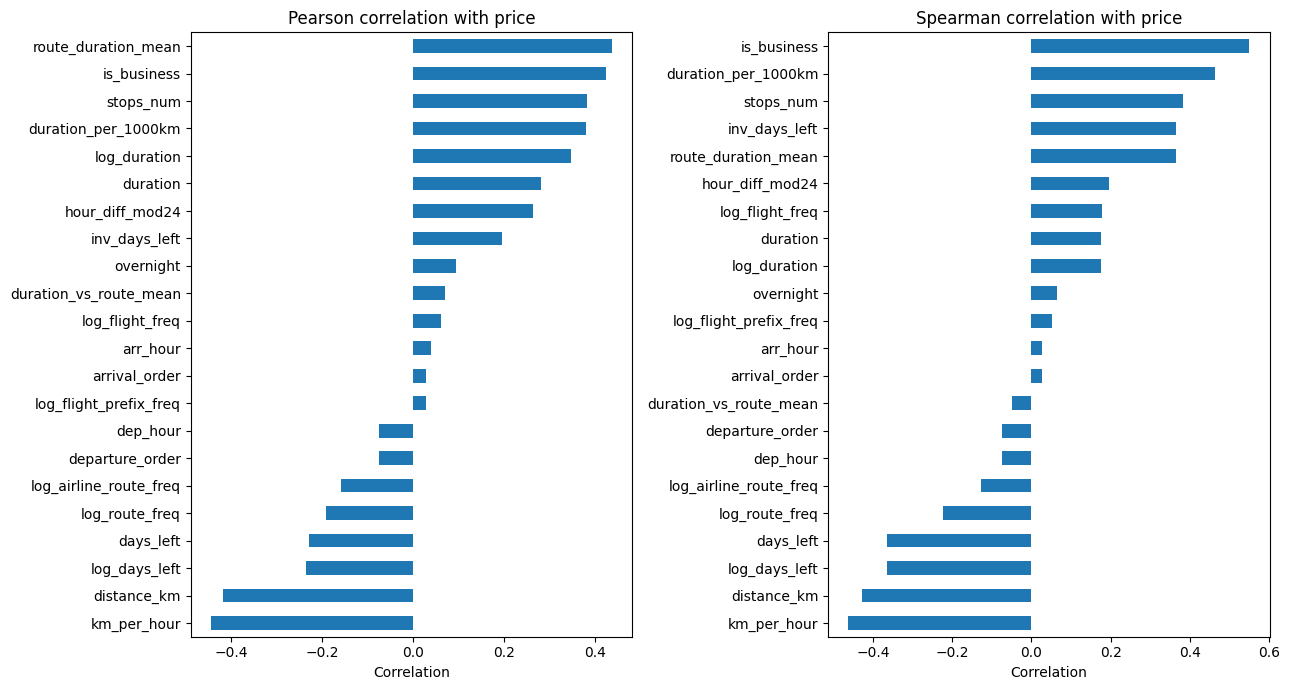

In [11]:
F_corr, _ = build_feature_frames(train, test)
_, engineered_nums = FEATURE_SETS["extended"]
eng_corr_frame = F_corr[engineered_nums].copy()
eng_corr_frame["price"] = train["price"].to_numpy()
pearson_eng = eng_corr_frame.corr(method="pearson")["price"].drop("price").sort_values()
spearman_eng = eng_corr_frame.corr(method="spearman")["price"].drop("price").sort_values()
engineered_corr_summary = pd.DataFrame({"Pearson": pearson_eng, "Spearman": spearman_eng})
display(engineered_corr_summary.sort_values("Pearson", key=lambda s: s.abs(), ascending=False).round(3))
fig, axes = plt.subplots(1, 2, figsize=(13, 7))
engineered_corr_summary["Pearson"].sort_values().plot(kind="barh", ax=axes[0])
axes[0].set_title("Pearson correlation with price")
axes[0].set_xlabel("Correlation")
engineered_corr_summary["Spearman"].sort_values().plot(kind="barh", ax=axes[1])
axes[1].set_title("Spearman correlation with price")
axes[1].set_xlabel("Correlation")
plt.tight_layout()
plt.show()


## 7. Metrics and reusable cross-validation helpers

All candidates are evaluated after inverse-transforming predictions back into original price units. The notebook reports **R², RMSE and MAE** together. The competition's official metric should be checked on Kaggle; leaderboard values have behaved like an R²-style score, so R² is the default screening metric here.

In [12]:
y = train["price"].to_numpy(dtype=float)

TARGET_MODES = {
    "log_huber": {"objective": "huber", "transform": lambda a: np.log1p(np.clip(a, 0, None)), "inverse": lambda a: np.expm1(a)},
    "log_l2":    {"objective": "regression", "transform": lambda a: np.log1p(np.clip(a, 0, None)), "inverse": lambda a: np.expm1(a)},
    "sqrt_l2":   {"objective": "regression", "transform": lambda a: np.sqrt(np.clip(a, 0, None)), "inverse": lambda a: np.square(np.clip(a, 0, None))},
    "raw_l2":    {"objective": "regression", "transform": lambda a: np.asarray(a, dtype=float), "inverse": lambda a: np.asarray(a, dtype=float)},
    "raw_huber": {"objective": "huber", "transform": lambda a: np.asarray(a, dtype=float), "inverse": lambda a: np.asarray(a, dtype=float)},
}

BASE_CFG = dict(n_estimators=LGB_TREES, learning_rate=0.03, num_leaves=63,
                subsample=0.8, colsample_bytree=0.8, subsample_freq=1,
                reg_alpha=0.0, reg_lambda=1.0, verbosity=-1, n_jobs=N_JOBS)
V4_CFG = {**BASE_CFG, "objective": "huber"}


def metric_dict(y_true, pred):
    pred = np.maximum(np.asarray(pred, dtype=float), 0)
    return {
        "r2": float(r2_score(y_true, pred)),
        "rmse": float(np.sqrt(mean_squared_error(y_true, pred))),
        "mae": float(mean_absolute_error(y_true, pred)),
    }


def fit_lgb_predict(X_fit, y_fit, X_apply, cat_cols, target_mode="log_huber", cfg=None, seed=SEED):
    cfg = dict(BASE_CFG if cfg is None else cfg)
    cfg["objective"] = TARGET_MODES[target_mode]["objective"]
    cfg["random_state"] = seed
    target = TARGET_MODES[target_mode]["transform"](y_fit)
    model = lgb.LGBMRegressor(**cfg)
    model.fit(X_fit, target, categorical_feature=cat_cols)
    raw_pred = model.predict(X_apply)
    pred = TARGET_MODES[target_mode]["inverse"](raw_pred)
    return np.maximum(np.asarray(pred, dtype=float), 0), model


def run_lgb_cv(raw, y_all, feature_set, target_mode, cfg=None, seeds=None, class_specific=False, candidate=None):
    """Repeated KFold CV. Fold-specific feature mappings are fitted using outer-train predictors only."""
    seeds = CV_SEEDS if seeds is None else seeds
    name = candidate or f"{feature_set}_{target_mode}" + ("_class_specific" if class_specific else "")
    rows = []
    pooled_oof = {}
    for split_seed in seeds:
        kf = KFold(n_splits=N_SPLITS, shuffle=True, random_state=split_seed)
        oof = np.zeros(len(raw), dtype=float)
        for fold_no, (tr_idx, va_idx) in enumerate(kf.split(raw), 1):
            Xtr, Xva, cats, nums, raw_tr_feat, raw_va_feat = make_feature_pair(raw.iloc[tr_idx], raw.iloc[va_idx], feature_set)
            ytr = y_all[tr_idx]
            if not class_specific:
                pred, _ = fit_lgb_predict(Xtr, ytr, Xva, cats, target_mode, cfg, seed=split_seed + fold_no)
                oof[va_idx] = pred
            else:
                # Separate regressors are trained within the outer training fold only.
                va_classes = raw.iloc[va_idx]["flight_class"].astype(str).to_numpy()
                tr_classes = raw.iloc[tr_idx]["flight_class"].astype(str).to_numpy()
                for cls in np.unique(va_classes):
                    tr_mask = tr_classes == cls
                    va_mask = va_classes == cls
                    Xtr_c, Xva_c = Xtr.iloc[tr_mask].copy(), Xva.iloc[va_mask].copy()
                    Xtr_c, Xva_c = prepare_lgb_pair(Xtr_c, Xva_c, cats)
                    p, _ = fit_lgb_predict(Xtr_c, ytr[tr_mask], Xva_c, cats, target_mode, cfg, seed=split_seed + fold_no)
                    oof[va_idx[va_mask]] = p
        pooled_oof[split_seed] = oof
        rows.append({"candidate": name, "seed": split_seed, **metric_dict(y_all, oof)})
        print(f"{name:34s} seed={split_seed}: R2={rows[-1]['r2']:.5f} RMSE={rows[-1]['rmse']:.3f} MAE={rows[-1]['mae']:.3f}")
    return pd.DataFrame(rows), pooled_oof

## 8. Experiment A — target transformations

The same LightGBM feature set and splits are used for `log1p(price)` + Huber, `log1p(price)` + squared error, `sqrt(price)` + squared error, raw-price squared error, and raw-price Huber. Transformed targets are converted back before calculating metrics. This is the cleanest way to isolate the effect of target scale.

In [13]:
transform_candidates = [
    ("V4 log + Huber", "v4", "log_huber"),
    ("V4 log + L2", "v4", "log_l2"),
    ("V4 sqrt + L2", "v4", "sqrt_l2"),
    ("V4 raw + L2", "v4", "raw_l2"),
    ("V4 raw + Huber", "v4", "raw_huber"),
]
transform_results = []
transform_oof = {}
for label, feature_set, target_mode in transform_candidates:
    res, oof = run_lgb_cv(train, y, feature_set, target_mode, cfg=BASE_CFG, candidate=label)
    transform_results.append(res)
    transform_oof[label] = oof
transform_results = pd.concat(transform_results, ignore_index=True)
print("\nSummary across split seeds:")
display(transform_results.groupby("candidate").agg(r2_mean=("r2", "mean"), r2_std=("r2", "std"), rmse_mean=("rmse", "mean"), mae_mean=("mae", "mean")).sort_values("r2_mean", ascending=False))

V4 log + Huber                     seed=42: R2=0.70278 RMSE=121.008 MAE=40.507
V4 log + Huber                     seed=7: R2=0.69673 RMSE=122.232 MAE=40.704
V4 log + Huber                     seed=2024: R2=0.70072 RMSE=121.427 MAE=40.600
V4 log + L2                        seed=42: R2=0.69366 RMSE=122.850 MAE=42.094
V4 log + L2                        seed=7: R2=0.68624 RMSE=124.328 MAE=42.178
V4 log + L2                        seed=2024: R2=0.68621 RMSE=124.335 MAE=42.498
V4 sqrt + L2                       seed=42: R2=0.70461 RMSE=120.633 MAE=42.223
V4 sqrt + L2                       seed=7: R2=0.69469 RMSE=122.642 MAE=42.456
V4 sqrt + L2                       seed=2024: R2=0.70087 RMSE=121.395 MAE=42.579
V4 raw + L2                        seed=42: R2=0.68972 RMSE=123.638 MAE=46.223
V4 raw + L2                        seed=7: R2=0.67464 RMSE=126.607 MAE=46.547
V4 raw + L2                        seed=2024: R2=0.68363 RMSE=124.844 MAE=46.395
V4 raw + Huber                     seed=42: R2=0

,r2_mean,r2_std,rmse_mean,mae_mean
candidate,,,,
V4 log + Huber,0.700075,0.003072,121.555633,40.603533
V4 sqrt + L2,0.700061,0.005010,121.556816,42.419204
V4 log + L2,0.688704,0.004293,123.837700,42.256587
V4 raw + L2,0.682662,0.007585,125.029711,46.388358
V4 raw + Huber,0.094124,0.000240,211.255062,120.020658


## 9. Experiment B — feature ablation

This compares feature sets under the **same log-target Huber objective**. Features added here are ordinary flight descriptors, approximate geography, and counts from predictor columns only. No ID position or neighbouring-price signals are used.

In [14]:
feature_candidates = [
    ("V4 only", "v4"),
    ("V4 + frequency", "frequency"),
    ("V4 + distance", "distance"),
    ("V4 + frequency + distance", "extended"),
]
feature_results = []
feature_oof = {}
for label, feature_set in feature_candidates:
    res, oof = run_lgb_cv(train, y, feature_set, "log_huber", cfg=BASE_CFG, candidate=label)
    feature_results.append(res)
    feature_oof[label] = oof
feature_results = pd.concat(feature_results, ignore_index=True)
print("\nSummary across split seeds:")
display(feature_results.groupby("candidate").agg(r2_mean=("r2", "mean"), r2_std=("r2", "std"), rmse_mean=("rmse", "mean"), mae_mean=("mae", "mean")).sort_values("r2_mean", ascending=False))

V4 only                            seed=42: R2=0.70278 RMSE=121.008 MAE=40.507
V4 only                            seed=7: R2=0.69673 RMSE=122.232 MAE=40.704
V4 only                            seed=2024: R2=0.70072 RMSE=121.427 MAE=40.600
V4 + frequency                     seed=42: R2=0.70221 RMSE=121.124 MAE=39.974
V4 + frequency                     seed=7: R2=0.69762 RMSE=122.053 MAE=39.993
V4 + frequency                     seed=2024: R2=0.70123 RMSE=121.323 MAE=40.187
V4 + distance                      seed=42: R2=0.70462 RMSE=120.633 MAE=40.250
V4 + distance                      seed=7: R2=0.69919 RMSE=121.735 MAE=40.464
V4 + distance                      seed=2024: R2=0.70335 RMSE=120.891 MAE=40.437
V4 + frequency + distance          seed=42: R2=0.70491 RMSE=120.572 MAE=39.774
V4 + frequency + distance          seed=7: R2=0.70222 RMSE=121.122 MAE=39.791
V4 + frequency + distance          seed=2024: R2=0.70556 RMSE=120.440 MAE=40.066

Summary across split seeds:


,r2_mean,r2_std,rmse_mean,mae_mean
candidate,,,,
V4 + frequency + distance,0.704229,0.001773,120.711599,39.877151
V4 + distance,0.702387,0.002837,121.086432,40.384024
V4 + frequency,0.700352,0.002414,121.499914,40.051264
V4 only,0.700075,0.003072,121.555633,40.603533


## 10. Experiment C — LightGBM regularization and tree complexity

A small, predeclared search tests shallower trees, stronger leaf-size constraints, and regularization. It is not an unlimited search over the public leaderboard. The chosen configuration is selected from cross-validation results, and all candidate configurations use identical folds.

In [15]:
if FAST_MODE:
    PARAM_CANDIDATES = [
        {"num_leaves": 31, "max_depth": 6, "min_child_samples": 40, "reg_lambda": 5.0, "reg_alpha": 0.0},
        {"num_leaves": 63, "max_depth": 8, "min_child_samples": 40, "reg_lambda": 5.0, "reg_alpha": 0.1},
    ]
else:
    PARAM_CANDIDATES = [
        {"num_leaves": 31, "max_depth": 6, "min_child_samples": 40, "reg_lambda": 5.0, "reg_alpha": 0.0},
        {"num_leaves": 63, "max_depth": 8, "min_child_samples": 40, "reg_lambda": 5.0, "reg_alpha": 0.1},
        {"num_leaves": 63, "max_depth": -1, "min_child_samples": 80, "reg_lambda": 10.0, "reg_alpha": 0.2},
        {"num_leaves": 95, "max_depth": 10, "min_child_samples": 40, "reg_lambda": 5.0, "reg_alpha": 0.1},
    ]

tune_rows = []
for i, params in enumerate(PARAM_CANDIDATES, 1):
    cfg = {**BASE_CFG, **params}
    label = f"extended_log_huber_cfg{i}"
    res, _ = run_lgb_cv(train, y, "extended", "log_huber", cfg=cfg, candidate=label)
    tune_rows.append({"candidate": label, **params,
                      "r2_mean": res["r2"].mean(), "r2_std": res["r2"].std(ddof=0),
                      "rmse_mean": res["rmse"].mean(), "mae_mean": res["mae"].mean()})
tuning_results = pd.DataFrame(tune_rows).sort_values("r2_mean", ascending=False).reset_index(drop=True)
display(tuning_results)

best_cfg_row = tuning_results.iloc[0]
best_cfg = {**BASE_CFG,
            "num_leaves": int(best_cfg_row["num_leaves"]),
            "max_depth": int(best_cfg_row["max_depth"]),
            "min_child_samples": int(best_cfg_row["min_child_samples"]),
            "reg_lambda": float(best_cfg_row["reg_lambda"]),
            "reg_alpha": float(best_cfg_row["reg_alpha"])}
print("Selected CV configuration (screening only):", best_cfg)

extended_log_huber_cfg1            seed=42: R2=0.69859 RMSE=121.858 MAE=41.457
extended_log_huber_cfg1            seed=7: R2=0.69588 RMSE=122.403 MAE=41.389
extended_log_huber_cfg1            seed=2024: R2=0.69779 RMSE=122.019 MAE=41.366
extended_log_huber_cfg2            seed=42: R2=0.70530 RMSE=120.493 MAE=40.280
extended_log_huber_cfg2            seed=7: R2=0.70118 RMSE=121.333 MAE=40.287
extended_log_huber_cfg2            seed=2024: R2=0.70363 RMSE=120.835 MAE=40.482
extended_log_huber_cfg3            seed=42: R2=0.69721 RMSE=122.137 MAE=41.082
extended_log_huber_cfg3            seed=7: R2=0.69447 RMSE=122.687 MAE=41.043
extended_log_huber_cfg3            seed=2024: R2=0.69545 RMSE=122.490 MAE=41.087
extended_log_huber_cfg4            seed=42: R2=0.70602 RMSE=120.345 MAE=40.086
extended_log_huber_cfg4            seed=7: R2=0.70145 RMSE=121.279 MAE=40.150
extended_log_huber_cfg4            seed=2024: R2=0.70258 RMSE=121.049 MAE=40.497


,candidate,num_leaves,max_depth,min_child_samples,reg_lambda,reg_alpha,r2_mean,r2_std,rmse_mean,mae_mean
0,extended_log_huber_cfg2,63,8,40,5.0,0.1,0.703369,0.001693,120.886969,40.349479
1,extended_log_huber_cfg4,95,10,40,5.0,0.1,0.703349,0.001947,120.890878,40.244559
2,extended_log_huber_cfg1,31,6,40,5.0,0.0,0.697419,0.001134,122.093581,41.404145
3,extended_log_huber_cfg3,63,-1,80,10.0,0.2,0.695709,0.001132,122.438011,41.070861


Selected CV configuration (screening only): {'n_estimators': 900, 'learning_rate': 0.03, 'num_leaves': 63, 'subsample': 0.8, 'colsample_bytree': 0.8, 'subsample_freq': 1, 'reg_alpha': 0.1, 'reg_lambda': 5.0, 'verbosity': -1, 'n_jobs': 4, 'max_depth': 8, 'min_child_samples': 40}


## 11. Experiment D — separate Economy and Business regressors

A single model must fit both pricing regimes. Here, each class gets a separate LightGBM regressor trained only on the relevant class within each outer training fold. This is evaluated against the global extended-feature model using square-root targets. It is a hypothesis to test, not an assumed win.

In [16]:
class_results, class_oof = run_lgb_cv(
    train, y, "extended", "sqrt_l2", cfg=BASE_CFG, class_specific=True,
    candidate="class_specific_sqrt_lgbm"
)
display(class_results)

class_specific_sqrt_lgbm           seed=42: R2=0.69363 RMSE=122.856 MAE=42.575
class_specific_sqrt_lgbm           seed=7: R2=0.68369 RMSE=124.833 MAE=42.764
class_specific_sqrt_lgbm           seed=2024: R2=0.69587 RMSE=122.406 MAE=42.696


,candidate,seed,r2,rmse,mae
0,class_specific_sqrt_lgbm,42,0.693630,122.855847,42.574643
1,class_specific_sqrt_lgbm,7,0.683688,124.833276,42.763919
2,class_specific_sqrt_lgbm,2024,0.695868,122.406276,42.696003


## 12. Experiment E — standalone CatBoost with native categorical features

CatBoost handles categorical features natively. This experiment uses the same outer folds and original-scale evaluation. Its numeric features include flight characteristics, count features and approximate geographic features. It uses a square-root target as a candidate, not as a foregone conclusion.

In [17]:
def prepare_cat_pair(X_fit, X_apply, cat_cols):
    A, B = X_fit.copy(), X_apply.copy()
    for c in cat_cols:
        A[c] = A[c].astype(object).where(A[c].notna(), "__NA__").astype(str)
        B[c] = B[c].astype(object).where(B[c].notna(), "__NA__").astype(str)
    for c in A.columns:
        if c not in cat_cols:
            A[c] = pd.to_numeric(A[c], errors="coerce").replace([np.inf, -np.inf], np.nan).fillna(-1)
            B[c] = pd.to_numeric(B[c], errors="coerce").replace([np.inf, -np.inf], np.nan).fillna(-1)
    return A, B


if FAST_MODE:
    CAT_PARAM_CANDIDATES = [
        {"iterations": CAT_TREES, "depth": 6, "learning_rate": 0.04, "l2_leaf_reg": 8.0},
        {"iterations": CAT_TREES, "depth": 7, "learning_rate": 0.03, "l2_leaf_reg": 12.0},
    ]
else:
    CAT_PARAM_CANDIDATES = [
        {"iterations": CAT_TREES, "depth": 6, "learning_rate": 0.03, "l2_leaf_reg": 8.0},
        {"iterations": CAT_TREES, "depth": 7, "learning_rate": 0.03, "l2_leaf_reg": 12.0},
        {"iterations": CAT_TREES, "depth": 8, "learning_rate": 0.04, "l2_leaf_reg": 10.0},
    ]


def run_catboost_cv(raw, y_all, feature_set="extended", seeds=None):
    if not CATBOOST_AVAILABLE:
        print("Skipping CatBoost CV: catboost is not installed.")
        return pd.DataFrame(), {}, {"iterations": CAT_TREES, "depth": 7, "learning_rate": 0.04, "l2_leaf_reg": 8.0}
    seeds = CV_SEEDS if seeds is None else seeds
    cat_cols_base, num_cols = FEATURE_SETS[feature_set]
    cat_cols = list(dict.fromkeys(cat_cols_base + [c for c in ["flight", "stops", "flight_class", "flight_route"] if c in deterministic_features(raw).columns]))
    rows, all_oof = [], {}
    for cfg in CAT_PARAM_CANDIDATES:
        candidate_name = f"catboost_sqrt_depth{cfg['depth']}_lr{cfg['learning_rate']}_l2{cfg['l2_leaf_reg']}"
        for split_seed in seeds:
            oof = np.zeros(len(raw), dtype=float)
            kf = KFold(n_splits=N_SPLITS, shuffle=True, random_state=split_seed)
            for fold_no, (tr_idx, va_idx) in enumerate(kf.split(raw), 1):
                Ft, Fv = build_feature_frames(raw.iloc[tr_idx], raw.iloc[va_idx])
                Xtr, _, _ = select_features(Ft, feature_set)
                Xva, _, _ = select_features(Fv, feature_set)
                for c in ["flight", "stops", "flight_class", "flight_route"]:
                    if c in Ft.columns and c not in Xtr.columns:
                        Xtr[c] = Ft[c].astype(str)
                        Xva[c] = Fv[c].astype(str)
                Xtr, Xva = prepare_cat_pair(Xtr, Xva, cat_cols)
                ytr = np.sqrt(np.clip(y_all[tr_idx], 0, None))
                model = CatBoostRegressor(
                    iterations=int(cfg["iterations"]), learning_rate=float(cfg["learning_rate"]),
                    depth=int(cfg["depth"]), l2_leaf_reg=float(cfg["l2_leaf_reg"]),
                    loss_function="RMSE", random_seed=split_seed + fold_no,
                    verbose=False, allow_writing_files=False, thread_count=N_JOBS
                )
                # The early-stopping subset comes only from the outer training fold.
                fit_idx, es_idx = train_test_split(np.arange(len(Xtr)), test_size=0.15, random_state=split_seed + fold_no)
                model.fit(Xtr.iloc[fit_idx], ytr[fit_idx], cat_features=cat_cols,
                          eval_set=(Xtr.iloc[es_idx], ytr[es_idx]), early_stopping_rounds=80,
                          verbose=False, use_best_model=True)
                oof[va_idx] = np.maximum(model.predict(Xva), 0) ** 2
            all_oof[(candidate_name, split_seed)] = oof
            row = {"candidate": candidate_name, "seed": split_seed, **metric_dict(y_all, oof)}
            rows.append(row)
            print(f"{candidate_name} seed={split_seed}: R2={row['r2']:.5f} RMSE={row['rmse']:.3f} MAE={row['mae']:.3f}")
    result = pd.DataFrame(rows)
    summary = result.groupby("candidate").agg(r2_mean=("r2", "mean"), r2_std=("r2", "std"), rmse_mean=("rmse", "mean"), mae_mean=("mae", "mean")).sort_values("r2_mean", ascending=False)
    best_name = summary.index[0]
    match = re.search(r"depth(\d+)_lr([0-9.]+)_l2([0-9.]+)", best_name)
    best_cfg = {"iterations": int(CAT_TREES), "depth": int(match.group(1)), "learning_rate": float(match.group(2)), "l2_leaf_reg": float(match.group(3))}
    display(summary)
    print("Selected CatBoost configuration based on CV mean R2:", best_cfg)
    return result, all_oof, best_cfg


cat_results, cat_oof, best_cat_cfg = run_catboost_cv(train, y, feature_set="extended")
if len(cat_results):
    display(cat_results)


catboost_sqrt_depth6_lr0.03_l28.0 seed=42: R2=0.68058 RMSE=125.445 MAE=49.260
catboost_sqrt_depth6_lr0.03_l28.0 seed=7: R2=0.67836 RMSE=125.880 MAE=48.977
catboost_sqrt_depth6_lr0.03_l28.0 seed=2024: R2=0.67704 RMSE=126.139 MAE=49.058
catboost_sqrt_depth7_lr0.03_l212.0 seed=42: R2=0.67969 RMSE=125.621 MAE=49.165
catboost_sqrt_depth7_lr0.03_l212.0 seed=7: R2=0.67908 RMSE=125.740 MAE=48.854
catboost_sqrt_depth7_lr0.03_l212.0 seed=2024: R2=0.67075 RMSE=127.360 MAE=49.269
catboost_sqrt_depth8_lr0.04_l210.0 seed=42: R2=0.68981 RMSE=123.620 MAE=46.820
catboost_sqrt_depth8_lr0.04_l210.0 seed=7: R2=0.68460 RMSE=124.654 MAE=46.789
catboost_sqrt_depth8_lr0.04_l210.0 seed=2024: R2=0.68175 RMSE=125.216 MAE=46.860


,r2_mean,r2_std,rmse_mean,mae_mean
candidate,,,,
catboost_sqrt_depth8_lr0.04_l210.0,0.685384,0.004088,124.496437,46.823013
catboost_sqrt_depth6_lr0.03_l28.0,0.678660,0.001789,125.821273,49.098239
catboost_sqrt_depth7_lr0.03_l212.0,0.676505,0.004991,126.240286,49.096053


Selected CatBoost configuration based on CV mean R2: {'iterations': 1200, 'depth': 8, 'learning_rate': 0.04, 'l2_leaf_reg': 10.0}


,candidate,seed,r2,rmse,mae
0,catboost_sqrt_depth6_lr0.03_l28.0,42,0.680580,125.445202,49.259821
1,catboost_sqrt_depth6_lr0.03_l28.0,7,0.678361,125.880038,48.976666
2,catboost_sqrt_depth6_lr0.03_l28.0,2024,0.677039,126.138579,49.058229
3,catboost_sqrt_depth7_lr0.03_l212.0,42,0.679685,125.620714,49.165423
4,catboost_sqrt_depth7_lr0.03_l212.0,7,0.679077,125.739977,48.854151
5,catboost_sqrt_depth7_lr0.03_l212.0,2024,0.670753,127.360169,49.268585
6,catboost_sqrt_depth8_lr0.04_l210.0,42,0.689808,123.619852,46.819726
7,catboost_sqrt_depth8_lr0.04_l210.0,7,0.684599,124.653537,46.789114
8,catboost_sqrt_depth8_lr0.04_l210.0,2024,0.681746,125.215921,46.860199


## 13. Experiment F — XGBoost standalone screen

XGBoost is permitted by the TA. This controlled screen uses the extended, ID-free flight features, fold-fitted preprocessing and a square-root target. It is a model comparison, not a guarantee that XGBoost will outperform LightGBM. It runs three folds with one split seed to keep runtime manageable; use repeated seeds only if the screen looks competitive.


In [18]:
try:
    from xgboost import XGBRegressor
    from sklearn.compose import ColumnTransformer
    from sklearn.preprocessing import OneHotEncoder
    from sklearn.pipeline import Pipeline
    XGBOOST_AVAILABLE = True
except Exception as exc:
    XGBOOST_AVAILABLE = False
    print("XGBoost unavailable; skipping screen:", repr(exc))

xgb_screen_results = pd.DataFrame()
if XGBOOST_AVAILABLE:
    xgb_rows = []
    xgb_seed = 42
    xgb_kf = KFold(n_splits=3, shuffle=True, random_state=xgb_seed)
    for fold_no, (tr_idx, va_idx) in enumerate(xgb_kf.split(train), 1):
        Ftr, Fva = build_feature_frames(train.iloc[tr_idx], train.iloc[va_idx])
        Xtr, cats, nums = select_features(Ftr, "extended")
        Xva, _, _ = select_features(Fva, "extended")
        prep = ColumnTransformer([
            ("cat", OneHotEncoder(handle_unknown="ignore"), cats),
            ("num", "passthrough", nums),
        ], remainder="drop")
        model = XGBRegressor(
            n_estimators=400, max_depth=5, learning_rate=0.04,
            subsample=0.8, colsample_bytree=0.8, min_child_weight=5,
            reg_lambda=5.0, objective="reg:squarederror", tree_method="hist",
            n_jobs=N_JOBS, random_state=xgb_seed + fold_no,
        )
        pipe = Pipeline([("preprocess", prep), ("model", model)])
        pipe.fit(Xtr, np.sqrt(np.clip(y[tr_idx], 0, None)))
        pred = np.square(np.maximum(pipe.predict(Xva), 0))
        metrics = metric_dict(y[va_idx], pred)
        xgb_rows.append({"candidate": "XGBoost sqrt target", "fold": fold_no, **metrics})
        print(f"XGBoost fold {fold_no}: R2={metrics['r2']:.5f}, RMSE={metrics['rmse']:.3f}, MAE={metrics['mae']:.3f}")
    xgb_screen_results = pd.DataFrame(xgb_rows)
    display(xgb_screen_results)
    print("Mean fold metrics:")
    display(xgb_screen_results[["r2", "rmse", "mae"]].mean().to_frame("mean").T.round(4))
    xgb_screen_results.to_csv(OUT_DIR / "xgboost_screen_results.csv", index=False)
else:
    print("No XGBoost results were generated in this environment.")


XGBoost fold 1: R2=0.69435, RMSE=125.636, MAE=45.177
XGBoost fold 2: R2=0.75572, RMSE=100.982, MAE=44.450
XGBoost fold 3: R2=0.62716, RMSE=142.401, MAE=44.699


,candidate,fold,r2,rmse,mae
0,XGBoost sqrt target,1,0.694352,125.635566,45.177441
1,XGBoost sqrt target,2,0.755721,100.982008,44.449507
2,XGBoost sqrt target,3,0.627157,142.401255,44.698923


Mean fold metrics:


,r2,rmse,mae
mean,0.6924,123.0063,44.7753


## 14. Experiment G — two-stage high-fare model

This experiment first estimates the probability that a fare is in the top 10% of the **outer training fold**, then fits separate low-fare and high-fare regressors. Predictions combine their conditional predictions using the estimated high-fare probability. The threshold is recomputed inside every fold, and no validation labels are used to define it.

This can help with different pricing regimes, but it can also amplify errors in the high-fare classifier. Keep it only if repeated CV supports it.

In [19]:
def fit_two_stage_predict(Xtr, ytr, Xva, cat_cols, seed, q=HIGH_FARE_QUANTILE):
    threshold = float(np.quantile(ytr, q))
    high_flag = (ytr >= threshold).astype(int)
    if high_flag.min() == high_flag.max():
        # Defensive fallback for unusual tiny or degenerate training folds.
        p, _ = fit_lgb_predict(Xtr, ytr, Xva, cat_cols, "sqrt_l2", cfg=BASE_CFG, seed=seed)
        return p, threshold

    clf_cfg = dict(n_estimators=100 if FAST_MODE else 600, learning_rate=0.04, num_leaves=31,
                   min_child_samples=40, reg_lambda=5.0, verbosity=-1, n_jobs=N_JOBS, random_state=seed)
    classifier = lgb.LGBMClassifier(**clf_cfg)
    classifier.fit(Xtr, high_flag, categorical_feature=cat_cols)
    p_high = classifier.predict_proba(Xva)[:, 1]

    low_mask, high_mask = ytr < threshold, ytr >= threshold
    low_model = lgb.LGBMRegressor(**{**BASE_CFG, "objective": "regression", "num_leaves": 31, "random_state": seed + 1})
    high_model = lgb.LGBMRegressor(**{**BASE_CFG, "objective": "regression", "num_leaves": 31, "min_child_samples": 10, "random_state": seed + 2})
    low_model.fit(Xtr.loc[low_mask], np.sqrt(np.clip(ytr[low_mask], 0, None)), categorical_feature=cat_cols)
    high_model.fit(Xtr.loc[high_mask], np.sqrt(np.clip(ytr[high_mask], 0, None)), categorical_feature=cat_cols)
    low_pred = np.maximum(low_model.predict(Xva), 0) ** 2
    high_pred = np.maximum(high_model.predict(Xva), 0) ** 2
    expected = (1.0 - p_high) * low_pred + p_high * high_pred
    return np.maximum(expected, 0), threshold


def run_two_stage_cv(raw, y_all, feature_set="extended", seeds=None):
    seeds = CV_SEEDS if seeds is None else seeds
    rows, oofs = [], {}
    for split_seed in seeds:
        oof = np.zeros(len(raw), dtype=float)
        kf = KFold(n_splits=N_SPLITS, shuffle=True, random_state=split_seed)
        thresholds = []
        for fold_no, (tr_idx, va_idx) in enumerate(kf.split(raw), 1):
            Xtr, Xva, cats, nums, _, _ = make_feature_pair(raw.iloc[tr_idx], raw.iloc[va_idx], feature_set)
            pred, threshold = fit_two_stage_predict(Xtr, y_all[tr_idx], Xva, cats, split_seed + fold_no)
            oof[va_idx] = pred
            thresholds.append(threshold)
        oofs[split_seed] = oof
        rows.append({"candidate": "two_stage_high_fare", "seed": split_seed, "mean_fold_threshold": float(np.mean(thresholds)), **metric_dict(y_all, oof)})
        print(f"two_stage_high_fare seed={split_seed}: R2={rows[-1]['r2']:.5f} RMSE={rows[-1]['rmse']:.3f} MAE={rows[-1]['mae']:.3f}")
    return pd.DataFrame(rows), oofs

two_stage_results, two_stage_oof = run_two_stage_cv(train, y, feature_set="extended")
display(two_stage_results)

two_stage_high_fare seed=42: R2=0.69016 RMSE=123.550 MAE=41.710
two_stage_high_fare seed=7: R2=0.68583 RMSE=124.409 MAE=41.801
two_stage_high_fare seed=2024: R2=0.68649 RMSE=124.280 MAE=41.999


,candidate,seed,mean_fold_threshold,r2,rmse,mae
0,two_stage_high_fare,42,517.066667,0.690159,123.549912,41.709753
1,two_stage_high_fare,7,518.333333,0.685834,124.409069,41.800790
2,two_stage_high_fare,2024,517.066667,0.686488,124.279606,41.998893


## 15. Experiment H — reproduce the V5-style target-encoding blend

This is the 70% V4 LightGBM + 30% target-encoded LightGBM blend family. Target encodings are smoothed averages of **training-fold targets** for categories and combined categories, cross-fitted for the training rows. This is categorical-statistics feature engineering, not neighbouring-row/KNN inference. The previously scored `submission_v5_cv_blend.csv` must remain untouched; this CV and generated CSV are a reproduction attempt and may not be bit-identical.

In [20]:
def smoothed_encode(reference_values, reference_y, apply_values, smoothing=20.0):
    ref = pd.DataFrame({"key": pd.Series(reference_values).fillna("__NA__").astype(str).to_numpy(),
                        "target": np.asarray(reference_y, dtype=float)})
    stats = ref.groupby("key")["target"].agg(["mean", "count"])
    global_mean = float(np.mean(reference_y))
    enc_map = (stats["mean"] * stats["count"] + smoothing * global_mean) / (stats["count"] + smoothing)
    return pd.Series(apply_values).fillna("__NA__").astype(str).map(enc_map).fillna(global_mean).to_numpy(dtype=float)


def crossfit_target_encode(Ftr, ytr_log, Fva, cats=TE_CATS, seed=SEED, inner_splits=5, smoothing=20.0):
    """Return cross-fitted training encodings and validation encodings fit from all outer-train labels."""
    n = len(Ftr)
    n_inner = min(inner_splits, max(2, n // 10))
    enc_train = np.zeros((n, len(cats)), dtype=float)
    inner_cv = KFold(n_splits=n_inner, shuffle=True, random_state=seed)
    for inner_tr, inner_va in inner_cv.split(Ftr):
        for j, col in enumerate(cats):
            enc_train[inner_va, j] = smoothed_encode(Ftr.iloc[inner_tr][col], ytr_log[inner_tr], Ftr.iloc[inner_va][col], smoothing)
    enc_valid = np.column_stack([
        smoothed_encode(Ftr[col], ytr_log, Fva[col], smoothing) for col in cats
    ])
    train_enc = pd.DataFrame(enc_train, columns=[f"te_{c}" for c in cats])
    valid_enc = pd.DataFrame(enc_valid, columns=[f"te_{c}" for c in cats])
    return train_enc, valid_enc


def assemble_target_encoded_design(Ftr, Fva, ytr_log, seed):
    Etr, Eva = crossfit_target_encode(Ftr, ytr_log, Fva, seed=seed, inner_splits=5 if not FAST_MODE else 3)
    _, nums = FEATURE_SETS["v4"]
    Ctr, Cva = Ftr[BASE_CATS].copy(), Fva[BASE_CATS].copy()
    for c in BASE_CATS:
        Ctr[c] = Ctr[c].fillna("__NA__").astype(str)
        Cva[c] = Cva[c].fillna("__NA__").astype(str)
    Ntr, Nva = Ftr[nums].copy(), Fva[nums].copy()
    for c in nums:
        Ntr[c] = pd.to_numeric(Ntr[c], errors="coerce").replace([np.inf, -np.inf], np.nan).fillna(-1)
        Nva[c] = pd.to_numeric(Nva[c], errors="coerce").replace([np.inf, -np.inf], np.nan).fillna(-1)
    Xtr = pd.concat([Etr.reset_index(drop=True), Ntr.reset_index(drop=True), Ctr.reset_index(drop=True)], axis=1)
    Xva = pd.concat([Eva.reset_index(drop=True), Nva.reset_index(drop=True), Cva.reset_index(drop=True)], axis=1)
    Xtr, Xva = prepare_lgb_pair(Xtr, Xva, BASE_CATS)
    return Xtr, Xva, BASE_CATS


def run_v5_blend_cv(raw, y_all, seeds=None):
    seeds = CV_SEEDS if seeds is None else seeds
    rows, oofs = [], {}
    te_cfg = {**BASE_CFG, "objective": "huber", "n_estimators": (100 if FAST_MODE else 800), "learning_rate": 0.03, "num_leaves": 63}
    for split_seed in seeds:
        oof = np.zeros(len(raw), dtype=float)
        kf = KFold(n_splits=N_SPLITS, shuffle=True, random_state=split_seed)
        for fold_no, (tr_idx, va_idx) in enumerate(kf.split(raw), 1):
            Ftr, Fva = build_feature_frames(raw.iloc[tr_idx], raw.iloc[va_idx])
            Xtr, _, _ = select_features(Ftr, "v4")
            Xva, _, _ = select_features(Fva, "v4")
            Xtr, Xva = prepare_lgb_pair(Xtr, Xva, BASE_CATS)
            log_y = np.log1p(y_all[tr_idx])
            base_model = lgb.LGBMRegressor(**{**te_cfg, "random_state": split_seed + fold_no})
            base_model.fit(Xtr, log_y, categorical_feature=BASE_CATS)
            p_base = np.maximum(np.expm1(base_model.predict(Xva)), 0)

            Xte_tr, Xte_va, te_cat_cols = assemble_target_encoded_design(Ftr, Fva, log_y, seed=split_seed + fold_no)
            te_model = lgb.LGBMRegressor(**{**te_cfg, "random_state": split_seed + 100 + fold_no})
            te_model.fit(Xte_tr, log_y, categorical_feature=te_cat_cols)
            p_te = np.maximum(np.expm1(te_model.predict(Xte_va)), 0)
            oof[va_idx] = 0.70 * p_base + 0.30 * p_te
        oofs[split_seed] = oof
        rows.append({"candidate": "V5_style_70_30_blend_reproduction", "seed": split_seed, **metric_dict(y_all, oof)})
        print(f"V5-style blend seed={split_seed}: R2={rows[-1]['r2']:.5f} RMSE={rows[-1]['rmse']:.3f} MAE={rows[-1]['mae']:.3f}")
    return pd.DataFrame(rows), oofs

v5_blend_results, v5_blend_oof = run_v5_blend_cv(train, y)
display(v5_blend_results)

V5-style blend seed=42: R2=0.70260 RMSE=121.045 MAE=40.362
V5-style blend seed=7: R2=0.69605 RMSE=122.369 MAE=40.357
V5-style blend seed=2024: R2=0.69944 RMSE=121.684 MAE=40.480


,candidate,seed,r2,rmse,mae
0,V5_style_70_30_blend_reproduction,42,0.702596,121.044817,40.361915
1,V5_style_70_30_blend_reproduction,7,0.696054,122.368897,40.356960
2,V5_style_70_30_blend_reproduction,2024,0.699445,121.684356,40.479778


## 16. Consolidate results and compare experiments

This summary combines every experiment above. A small CV gain should not automatically trigger a leaderboard submission: compare the mean across seeds, its variability, RMSE/MAE, and whether the gain repeats on the same splits. A high-fare specialist may improve R² while harming MAE, so inspect all metrics.

In [21]:
all_result_frames = [transform_results, feature_results, tuning_results.assign(seed_summary="tuning")]
all_result_frames.append(class_results)
if len(cat_results): all_result_frames.append(cat_results)
all_result_frames.append(two_stage_results)
all_result_frames.append(v5_blend_results)

# Normalize different result table schemas into an easy-to-read log.
normalized = []
for df in all_result_frames:
    if df is None or len(df) == 0:
        continue
    if "seed" in df.columns and {"r2", "rmse", "mae"}.issubset(df.columns):
        normalized.append(df[[c for c in ["candidate", "seed", "r2", "rmse", "mae"] if c in df.columns]].copy())
    elif {"candidate", "r2_mean", "rmse_mean", "mae_mean"}.issubset(df.columns):
        tmp = df[["candidate", "r2_mean", "r2_std", "rmse_mean", "mae_mean"]].copy()
        tmp = tmp.rename(columns={"r2_mean": "r2", "rmse_mean": "rmse", "mae_mean": "mae"})
        tmp["seed"] = "CV mean"
        normalized.append(tmp[["candidate", "seed", "r2", "rmse", "mae"]])
all_results = pd.concat(normalized, ignore_index=True, sort=False)
summary = all_results.groupby("candidate").agg(
    r2_mean=("r2", "mean"), r2_std=("r2", "std"), rmse_mean=("rmse", "mean"), mae_mean=("mae", "mean")
).sort_values("r2_mean", ascending=False).reset_index()
display(summary)

OUT_DIR = Path("/kaggle/working") if Path("/kaggle/working").exists() else Path.cwd()
OUT_DIR.mkdir(parents=True, exist_ok=True)
all_results.to_csv(OUT_DIR / "v6_experiment_log.csv", index=False)
summary.to_csv(OUT_DIR / "v6_experiment_summary.csv", index=False)
tuning_results.to_csv(OUT_DIR / "v6_lightgbm_tuning.csv", index=False)
print("Saved experiment log to:", OUT_DIR)
print("Best confirmed Kaggle score reported by user: 0.78042 (submission_v6_sqrt_lgbm.csv). Earlier V5 score: 0.77602.")

,candidate,r2_mean,r2_std,rmse_mean,mae_mean
0,V4 + frequency + distance,0.704229,0.001773,120.711599,39.877151
1,extended_log_huber_cfg2,0.703369,NaN,120.886969,40.349479
2,extended_log_huber_cfg4,0.703349,NaN,120.890878,40.244559
3,V4 + distance,0.702387,0.002837,121.086432,40.384024
4,V4 + frequency,0.700352,0.002414,121.499914,40.051264
5,V4 log + Huber,0.700075,0.003072,121.555633,40.603533
6,V4 only,0.700075,0.003072,121.555633,40.603533
7,V4 sqrt + L2,0.700061,0.005010,121.556816,42.419204
8,V5_style_70_30_blend_reproduction,0.699365,0.003272,121.699357,40.399551
9,extended_log_huber_cfg1,0.697419,NaN,122.093581,41.404145


Saved experiment log to: /kaggle/working
Best confirmed Kaggle score reported by user: 0.78042 (submission_v6_sqrt_lgbm.csv). Earlier V5 score: 0.77602.


## 17. Fit candidate models and write experimental submissions

This section fits candidate models on the full labelled training data. It writes **new V6 filenames only** and does not overwrite `submission_v5_cv_blend.csv` or any earlier best file. Candidate CSVs have not been scored by Kaggle until you upload them.

Candidates:

- V5-style blend reproduction (for reproducibility comparison; may not be bit-identical to the already-scored CSV)
- Square-root LightGBM on extended features
- CV-selected LightGBM configuration on extended features
- Separate Economy / Business square-root LightGBM
- CatBoost with native categorical handling (if installed)
- Two-stage high-fare model

In `FAST_MODE`, final candidates use one seed for quick testing. Set `FAST_MODE=False` before producing serious candidates for Kaggle.

In [26]:
def final_feature_pair(raw_fit, raw_apply, feature_set):
    return make_feature_pair(raw_fit, raw_apply, feature_set)


def final_lgb_candidate(raw_fit, y_fit, raw_apply, feature_set, target_mode, cfg, seeds):
    Xtr, Xte, cats, nums, Ftr, Fte = final_feature_pair(raw_fit, raw_apply, feature_set)
    preds = []
    for s in seeds:
        p, _ = fit_lgb_predict(Xtr, y_fit, Xte, cats, target_mode, cfg=cfg, seed=s)
        preds.append(p)
    return np.mean(preds, axis=0)


def final_class_specific_candidate(raw_fit, y_fit, raw_apply, feature_set="extended", seeds=None):
    seeds = FINAL_SEEDS if seeds is None else seeds
    Xtr, Xte, cats, nums, Ftr, Fte = final_feature_pair(raw_fit, raw_apply, feature_set)
    output = np.zeros(len(raw_apply), dtype=float)
    test_classes = raw_apply["flight_class"].astype(str).to_numpy()
    train_classes = raw_fit["flight_class"].astype(str).to_numpy()
    for cls in np.unique(test_classes):
        tr_mask, te_mask = train_classes == cls, test_classes == cls
        Xtr_c, Xte_c = Xtr.iloc[tr_mask].copy(), Xte.iloc[te_mask].copy()
        Xtr_c, Xte_c = prepare_lgb_pair(Xtr_c, Xte_c, cats)
        preds = []
        for s in seeds:
            p, _ = fit_lgb_predict(Xtr_c, y_fit[tr_mask], Xte_c, cats, "sqrt_l2", cfg=BASE_CFG, seed=s)
            preds.append(p)
        output[te_mask] = np.mean(preds, axis=0)
    return output


def final_catboost_candidate(raw_fit, y_fit, raw_apply, feature_set="extended", seeds=None):
    if not CATBOOST_AVAILABLE:
        return None
    seeds = FINAL_SEEDS if seeds is None else seeds
    Ftr, Fte = build_feature_frames(raw_fit, raw_apply)
    cats, nums = FEATURE_SETS[feature_set]
    cat_cols = list(dict.fromkeys(list(cats) + [c for c in ["flight", "stops", "flight_class", "flight_route"] if c in Ftr.columns]))
    Xtr, _, _ = select_features(Ftr, feature_set)
    Xte, _, _ = select_features(Fte, feature_set)
    for c in ["flight", "stops", "flight_class", "flight_route"]:
        if c in Ftr.columns and c not in Xtr.columns:
            Xtr[c], Xte[c] = Ftr[c].astype(str), Fte[c].astype(str)
    Xtr, Xte = prepare_cat_pair(Xtr, Xte, cat_cols)
    preds = []
    for s in seeds:
        model = CatBoostRegressor(iterations=int(best_cat_cfg["iterations"]), learning_rate=float(best_cat_cfg["learning_rate"]),
                                  depth=int(best_cat_cfg["depth"]), l2_leaf_reg=float(best_cat_cfg["l2_leaf_reg"]),
                                  loss_function="RMSE", random_seed=s, verbose=False,
                                  allow_writing_files=False, thread_count=N_JOBS)
        model.fit(Xtr, np.sqrt(np.clip(y_fit, 0, None)), cat_features=cat_cols, verbose=False)
        preds.append(np.maximum(model.predict(Xte), 0) ** 2)
    return np.mean(preds, axis=0)


def final_two_stage_candidate(raw_fit, y_fit, raw_apply, feature_set="extended", seeds=None):
    seeds = FINAL_SEEDS if seeds is None else seeds
    Xtr, Xte, cats, nums, Ftr, Fte = final_feature_pair(raw_fit, raw_apply, feature_set)
    preds = []
    for s in seeds:
        threshold = float(np.quantile(y_fit, HIGH_FARE_QUANTILE))
        flags = (y_fit >= threshold).astype(int)
        clf = lgb.LGBMClassifier(n_estimators=100 if FAST_MODE else 600, learning_rate=0.04, num_leaves=31,
                                 min_child_samples=40, reg_lambda=5.0, verbosity=-1, n_jobs=N_JOBS, random_state=s)
        clf.fit(Xtr, flags, categorical_feature=cats)
        p_hi = clf.predict_proba(Xte)[:, 1]
        low, high = y_fit < threshold, y_fit >= threshold
        m_low = lgb.LGBMRegressor(**{**BASE_CFG, "objective": "regression", "num_leaves": 31, "random_state": s + 1})
        m_high = lgb.LGBMRegressor(**{**BASE_CFG, "objective": "regression", "num_leaves": 31, "min_child_samples": 10, "random_state": s + 2})
        m_low.fit(Xtr.loc[low], np.sqrt(np.clip(y_fit[low], 0, None)), categorical_feature=cats)
        m_high.fit(Xtr.loc[high], np.sqrt(np.clip(y_fit[high], 0, None)), categorical_feature=cats)
        p_low = np.maximum(m_low.predict(Xte), 0) ** 2
        p_high = np.maximum(m_high.predict(Xte), 0) ** 2
        preds.append((1 - p_hi) * p_low + p_hi * p_high)
    return np.mean(preds, axis=0)


def save_submission(filename, pred):
    pred = np.asarray(pred, dtype=float)
    sub = pd.DataFrame({"id": test["id"].to_numpy(), "price": np.maximum(pred, 0)})
    assert sub.shape == (4520, 2), sub.shape
    assert sub.columns.tolist() == ["id", "price"]
    assert np.array_equal(sub["id"].to_numpy(), test["id"].to_numpy())
    assert np.isfinite(sub["price"].to_numpy()).all()
    assert (sub["price"] >= 0).all()
    path = OUT_DIR / filename
    sub.to_csv(path, index=False)
    print(f"Saved {path.name} | shape={sub.shape} | pred min/median/mean/max="
          f"{sub.price.min():.2f}/{sub.price.median():.2f}/{sub.price.mean():.2f}/{sub.price.max():.2f}")
    return path

# 1. V5-style 70/30 blend reproduction: preserve the idea of the current winner.
Ftr, Fte = build_feature_frames(train, test)
Xv4_tr, _, _ = select_features(Ftr, "v4")
Xv4_te, _, _ = select_features(Fte, "v4")
Xv4_tr, Xv4_te = prepare_lgb_pair(Xv4_tr, Xv4_te, BASE_CATS)
log_y_full = np.log1p(y)
pred_v4_list = []
for s in FINAL_SEEDS:
    m = lgb.LGBMRegressor(**{**BASE_CFG, "objective": "huber", "n_estimators": (100 if FAST_MODE else 800), "learning_rate": 0.03, "num_leaves": 63, "random_state": s})
    m.fit(Xv4_tr, log_y_full, categorical_feature=BASE_CATS)
    pred_v4_list.append(np.maximum(np.expm1(m.predict(Xv4_te)), 0))
pred_v4 = np.mean(pred_v4_list, axis=0)
Xte_tr, Xte_te, te_cat_cols = assemble_target_encoded_design(Ftr, Fte, log_y_full, seed=2026)
pred_te_list = []
for s in FINAL_SEEDS:
    m = lgb.LGBMRegressor(**{**BASE_CFG, "objective": "huber", "n_estimators": (100 if FAST_MODE else 800), "learning_rate": 0.03, "num_leaves": 63, "random_state": s + 1})
    m.fit(Xte_tr, log_y_full, categorical_feature=te_cat_cols)
    pred_te_list.append(np.maximum(np.expm1(m.predict(Xte_te)), 0))
pred_te = np.mean(pred_te_list, axis=0)
pred_v5_style = 0.70 * pred_v4 + 0.30 * pred_te
save_submission("submission_v6_v5_style_blend_recreated.csv", pred_v5_style)

# 2. Square-root LightGBM on extended flight features.
pred_sqrt = final_lgb_candidate(train, y, test, "extended", "sqrt_l2", BASE_CFG, FINAL_SEEDS)
save_submission("submission_v6_sqrt_lgbm_fullfit.csv", pred_sqrt)

# 3. CV-selected regularized log-Huber LightGBM on extended features.
pred_tuned = final_lgb_candidate(train, y, test, "extended", "log_huber", best_cfg, FINAL_SEEDS)
save_submission("submission_v6_tuned_lgbm.csv", pred_tuned)

# 4. Separate Economy and Business square-root regressors.
pred_class = final_class_specific_candidate(train, y, test, feature_set="extended", seeds=FINAL_SEEDS)
save_submission("submission_v6_class_specific_sqrt.csv", pred_class)

# 5. Native-categorical CatBoost, if installed.
pred_cat = final_catboost_candidate(train, y, test, feature_set="extended", seeds=FINAL_SEEDS)
if pred_cat is not None:
    save_submission("submission_v6_catboost_sqrt.csv", pred_cat)

# 6. Two-stage high-fare model.
pred_two_stage = final_two_stage_candidate(train, y, test, feature_set="extended", seeds=FINAL_SEEDS)
save_submission("submission_v6_two_stage_high_fare.csv", pred_two_stage)

# Preserve the previously scored best CSV if it is present in this environment.
old_best = find_csv("submission_v5_cv_blend.csv", required=False)
if old_best is not None:
    print("Existing best submission file found and left untouched:", old_best)
else:
    print("Reminder: preserve the historically scored best file submission_v6_sqrt_lgbm.csv (reported public score 0.78042).")

Saved submission_v6_v5_style_blend_recreated.csv | shape=(4520, 2) | pred min/median/mean/max=29.10/237.29/273.61/2173.48
Saved submission_v6_sqrt_lgbm_fullfit.csv | shape=(4520, 2) | pred min/median/mean/max=0.49/238.11/277.75/2510.40
Saved submission_v6_tuned_lgbm.csv | shape=(4520, 2) | pred min/median/mean/max=29.50/237.46/273.97/2055.46
Saved submission_v6_class_specific_sqrt.csv | shape=(4520, 2) | pred min/median/mean/max=0.00/236.18/278.53/2649.46
Saved submission_v6_catboost_sqrt.csv | shape=(4520, 2) | pred min/median/mean/max=33.03/243.60/275.45/2272.59
Saved submission_v6_two_stage_high_fare.csv | shape=(4520, 2) | pred min/median/mean/max=11.63/240.60/279.28/2724.80
Reminder: preserve the historically scored best file submission_v6_sqrt_lgbm.csv (reported public score 0.78042).


## 18. Feature importance for the winning LightGBM configuration

This plot is computed from a LightGBM model trained on the full labelled data using the same configuration used for the highest-scoring square-root candidate. Importance is a model diagnostic, not causal evidence; correlated features can share or substitute for one another.


,feature,gain,split
7,airline_route,1630769.41,912
11,is_business,1603923.99,82
13,days_left,780842.17,1456
30,duration_per_1000km,404779.41,316
29,distance_km,235979.08,98
23,log_days_left,173067.74,267
31,km_per_hour,153827.72,79
27,log_airline_route_freq,110183.15,291
22,duration_vs_route_mean,96065.71,453
25,log_flight_freq,93916.54,468


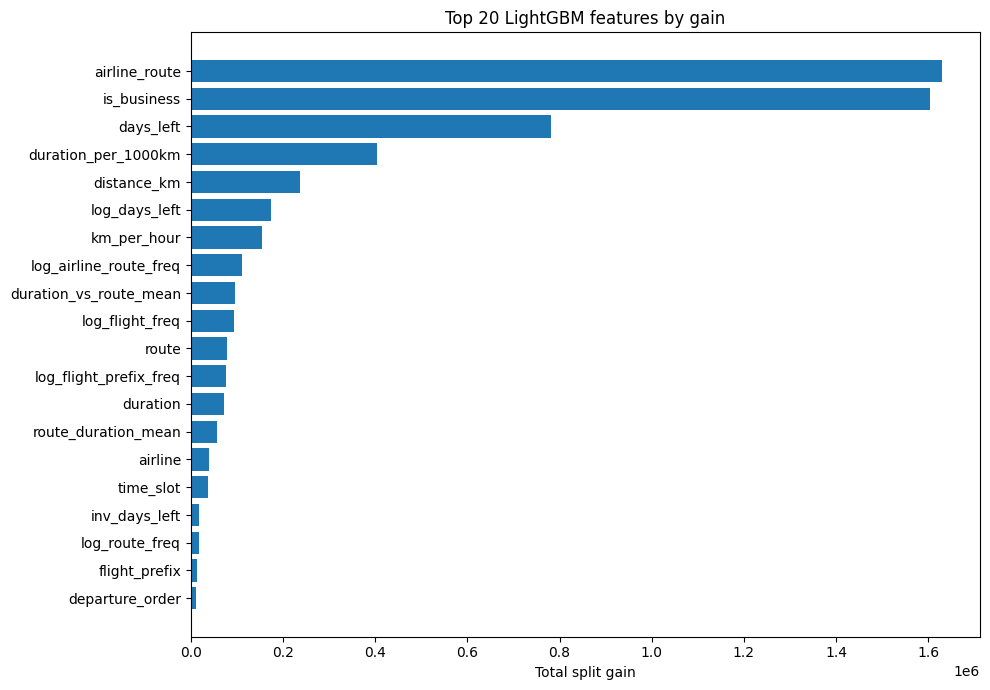

In [23]:
WINNING_SUBMISSION_CFG = {**BASE_CFG, "n_estimators": 100, "learning_rate": 0.03, "num_leaves": 63,
                          "subsample": 0.8, "colsample_bytree": 0.8, "subsample_freq": 1,
                          "reg_alpha": 0.0, "reg_lambda": 1.0}
X_full_win, X_test_win, win_cats, win_nums, F_full_win, F_test_win = make_feature_pair(train, test, "extended")
winning_model_for_importance = lgb.LGBMRegressor(**{**WINNING_SUBMISSION_CFG, "objective": "regression", "random_state": 42, "verbosity": -1, "n_jobs": N_JOBS})
winning_model_for_importance.fit(X_full_win, np.sqrt(np.clip(y, 0, None)), categorical_feature=win_cats)
importance = pd.DataFrame({"feature": X_full_win.columns,
                           "gain": winning_model_for_importance.booster_.feature_importance(importance_type="gain"),
                           "split": winning_model_for_importance.booster_.feature_importance(importance_type="split")})
importance = importance.sort_values("gain", ascending=False).head(20)
display(importance.round(2))
fig, ax = plt.subplots(figsize=(10, 7))
ax.barh(importance.sort_values("gain")["feature"], importance.sort_values("gain")["gain"])
ax.set_title("Top 20 LightGBM features by gain")
ax.set_xlabel("Total split gain")
plt.tight_layout()
plt.show()


## 19. Final output — reproduce the best-scoring LightGBM CSV

The user's highest confirmed public submission was produced by the following compact configuration: `sqrt(price)` target, extended flight features, 100 trees, learning rate 0.03, 63 leaves, row/feature subsampling at 0.8, and seed 42. This is intentionally kept separate from the larger CV experiment configurations above. The report of 0.78042 belongs to the previously uploaded Kaggle result; it is not computed from hidden labels here.


In [29]:
# # Recreate the exact configuration behind the previously scored candidate.
# WINNING_SUBMISSION_CFG = {**BASE_CFG, "n_estimators": 100, "learning_rate": 0.03, "num_leaves": 63,
#                           "subsample": 0.8, "colsample_bytree": 0.8, "subsample_freq": 1,
#                           "reg_alpha": 0.0, "reg_lambda": 1.0}
# winning_predictions = final_lgb_candidate(
#     train, y, test, feature_set="extended", target_mode="sqrt_l2",
#     cfg=WINNING_SUBMISSION_CFG, seeds=[42]
# )
# final_submission_path = save_submission("submission_v6_sqrt_lgbm_fullfit.csv", winning_predictions)
final_submission_path = Path(
    "/kaggle/working/submission_v6_sqrt_lgbm_fullfit.csv"
)

assert final_submission_path.exists(), (
    f"Submission file not found: {final_submission_path}"
)

final_submission = pd.read_csv(final_submission_path)

print("Reported past Kaggle score (user-provided): 0.78042")
print("Recreated submission shape:", final_submission.shape)
print("Column order:", final_submission.columns.tolist())

display(final_submission.head(10))

# Validate submission
assert final_submission.shape == (4520, 2)
assert final_submission.columns.tolist() == ["id", "price"]
assert np.array_equal(
    final_submission["id"].to_numpy(),
    test["id"].to_numpy()
)
assert np.isfinite(final_submission["price"].to_numpy()).all()
assert (final_submission["price"] >= 0).all()

print("All submission checks passed.")


Reported past Kaggle score (user-provided): 0.78042
Recreated submission shape: (4520, 2)
Column order: ['id', 'price']


,id,price
0,18395,61.012849
1,11771,168.836666
2,22326,325.919703
3,18332,131.772035
4,11021,545.630742
5,8614,211.774613
6,17654,149.721468
7,14898,147.423008
8,8794,141.291877
9,15325,193.656800


All submission checks passed.


## 20. Final checklist and how to use the results

1. The full experiment suite runs with `FAST_MODE=False`; `FAST_MODE=True` is only a quick smoke test. Do not use smoke-test CV scores for model selection.
2. The recommended run is `FAST_MODE=False`, which uses three independent fold seeds, three folds per seed, more trees, and multi-seed final fits.
3. Inspect `v6_experiment_summary.csv`; prefer gains that repeat across seeds and do not rely on a single lucky fold.
4. Compare the candidate CSVs on Kaggle one at a time. Preserve `submission_v6_sqrt_lgbm.csv`, the current best confirmed result reported at **0.78042**.
5. Only report a Kaggle score after Kaggle returns it. Cross-validation scores are local estimates, not leaderboard results.

### Recommended order

- The final section recreates `submission_v6_sqrt_lgbm.csv` using the compact configuration behind the known 0.78042 result.
- Then test `submission_v6_class_specific_sqrt.csv` or `submission_v6_tuned_lgbm.csv` if their repeated-CV results are competitive.
- Treat CatBoost and the two-stage model as experiments; keep them only if their validation and leaderboard results justify the added complexity.

### What not to use

This notebook intentionally excludes ID-order features, row/block positions, neighbouring training prices, interpolation from labelled neighbours, and nearest-row/KNN-like tricks because your TA said that approach is not allowed before KNN is taught.